# 03 · Predicting exploitation at publication (Q2)

**DSCI 510 project: Anticipating Attacks on Software Flaws**

This notebook answers the project's modelling question:

> **Q2.** Using only what is known on the day a CVE is published, can we rank new CVEs so that the
> ones later exploited come first, and do better than ranking by the publisher's severity score?

**How the answer is measured.** A security team can only handle part of what is published. So every
model is judged as a *ranking*: if the team handles the top 5%, 10% or 26% of new CVEs, what share of
the CVEs later exploited does it catch? That share is the **coverage**; the share handled is the
**effort**. 26% is the effort of the rule "patch every CVE scored 7.0 or higher", measured in
`02_descriptive_analysis.ipynb`, so it is the natural point of comparison. Accuracy is never used: a
model that flags nothing is 99.6% accurate.

| Stage | What happens |
|:--|:--|
| A · Setup | Settings, and the evaluation tools, tested on cases with known answers |
| B · Data | The analysis table, checked; a guard that only permitted inputs reach a model |
| C · Description audit | Do descriptions mention exploitation? Was that text added after publication? |
| D · Features | Structured fields and description text, learned from the training period only |
| E · Models | Baselines, logistic regression and gradient boosting, tuned on 2023 |
| F · Text and the PyTorch decision | What the description adds, and the go/no-go rule for the extension |
| G · The test year | The chosen models, refitted and scored once on 2024 (sealed by default) |
| H · Summary | Key findings, checks and files |

**Inputs:** `data/processed/analysis_table.parquet` and its column dictionary, the acquisition log,
and (optional, cached) publisher names from `02_descriptive_analysis.ipynb`.

**Outputs:** tables in `results/` (`q2_*.csv`, `q2_*.json`), figures in `figures/` (`q2_*.png`),
model scores in `data/processed/` for the EPSS comparison, and the run log `logs/model_log.json`
(`logs/model_log_test.json` in the test-year copy).

**A companion notebook:** `03b_random_split_check.ipynb` asks whether a random train/test split
would have told a different story than the time-based split used here. It reads this notebook's
frozen choices and 2023 scores, so run it after this one.

**Runtime:** about 2 minutes on a fast machine and about 7 on the laptop used for this project
(most of it fitting the 39 models in Step 15). The **first** run also asks the NVD
for the change history of about 150 CVEs (Step 10). The NVD takes 10–15 seconds to answer each
request, so this adds roughly 10 minutes, with a progress line every 25 CVEs. The answers are cached
in `data/raw/nvd_history/`, so later runs skip this, and an interrupted run keeps what it had fetched.

**The rule about the test year.** Every choice in this notebook (features, settings, which model is
best) is made on the training period (Nov 2021–2022) and the validation year (2023). The test year
(2024) stays **sealed**: with the setting `EVALUATE_TEST = False`, no 2024 label is read at all.

**Two copies of this notebook.** `03_model.ipynb` runs with the test year sealed and keeps the 2023
results on screen. `03_model_test.ipynb` is the same notebook, cell for cell, with one difference:
`EVALUATE_TEST = True`. Run it once, when the validation results are final. It makes every choice
again (identically), freezes them in `results/q2_selection.json` *before* 2024 is scored, and logs
the opening of the test year with that file's fingerprint. Each copy keeps its own run log and
summary (`model_log.json` / `q2_summary.json`, and `model_log_test.json` / `q2_summary_test.json`),
so both can be read side by side.

---

## Stage A · Setup

### Step 1 · Libraries

**What we are doing:** installing scikit-learn if it is missing, then importing the libraries and
recording their versions.

**Why:** scikit-learn provides the two model families and the text features; the versions are saved
in the run log, so the results can be reproduced later.

In [1]:
%pip install --quiet scikit-learn pyarrow

Note: you may need to restart the kernel to use updated packages.


**The imports:** the next cell loads everything the notebook uses and stops with a clear message if
scikit-learn is older than 1.2 (older versions lack options used here, such as `sparse_output`).

In [2]:
import hashlib, json, re, sys, threading, time
import datetime as dt
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import scipy.sparse as sp
import sklearn
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.ticker import PercentFormatter
from sklearn.decomposition import TruncatedSVD
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler

if tuple(int(part) for part in sklearn.__version__.split(".")[:2]) < (1, 2):
    raise RuntimeError(f"scikit-learn {sklearn.__version__} is too old: run the %pip cell above with "
                       "--upgrade, restart the kernel, and run the notebook again.")

VERSIONS = {"python": sys.version.split()[0], "pandas": pd.__version__, "numpy": np.__version__,
            "scikit-learn": sklearn.__version__, "matplotlib": matplotlib.__version__}
print(" | ".join(f"{name} {version}" for name, version in VERSIONS.items()))

python 3.14.6 | pandas 3.0.3 | numpy 2.4.6 | scikit-learn 1.9.0 | matplotlib 3.11.0


**Reading the result:** one line of versions. Any scikit-learn from 1.2 on works.

### Step 2 · Settings

**What we are doing:** fixing every setting in one place: folders, periods, the test-year switch,
the effort levels, the feature thresholds and the two model grids.

**Why:** each choice below is made once, here, with its reason, before any result is seen. The grids
are deliberately small: with 145 exploited CVEs in 2023, the validation year cannot tell apart many
near-identical settings, and trying many of them would only fit the noise of that one year.

In [3]:
# ---- Folders ----
PROCESSED, RAW = Path("data") / "processed", Path("data") / "raw"
RESULTS, FIGURES, LOGS = Path("results"), Path("figures"), Path("logs")
HISTORY_CACHE = RAW / "nvd_history"                        # one JSON file per CVE (Stage C)
for folder in (RESULTS, FIGURES, LOGS, HISTORY_CACHE):
    folder.mkdir(parents=True, exist_ok=True)

# ---- Periods, label and the test-year switch ----
PERIODS = ["train", "validate", "test"]
PERIOD_NAMES = {"train": "Nov 2021–2022", "validate": "2023", "test": "2024"}
LABEL = "label_365"                       # listed in KEV within 365 calendar days of publication
EVALUATE_TEST = False                     # True only once the validation results are final (Stage G)

# ---- Evaluation ----
SEED, N_BOOT = 510, 1000                  # fixed seed: bootstrap intervals repeat exactly
EFFORTS = [0.05, 0.10, 0.26]              # shares of new CVEs handled; 0.26 = the 'score 7.0+' rule
PRIMARY_EFFORT = 0.10                     # the effort used to choose between models

# ---- Features ----
MIN_CATEGORY = 20                         # CVEs a publisher or CWE needs in the fitting data to get its own column
MAX_CATEGORIES = 250                      # gradient boosting accepts at most 255 categories per column
TFIDF = {"ngram_range": (1, 2), "min_df": 5, "max_df": 0.5, "max_features": 50_000,
         "sublinear_tf": True, "stop_words": "english"}
SVD_COMPONENTS = 100                      # dense summary of the text for gradient boosting

# ---- Model grids ----
LR_GRID = [{"C": c} for c in (0.01, 0.03, 0.1, 0.3, 1.0)]
GBM_GRID = [{"max_iter": n, "max_leaf_nodes": leaves, "min_samples_leaf": leaf}
            for n in (100, 300) for leaves in (7, 15) for leaf in (20, 80)]

# ---- Description audit (Stage C) and the PyTorch rule (Stage F) ----
HISTORY_URL = "https://services.nvd.nist.gov/rest/json/cvehistory/2.0"
HISTORY_MAX, HISTORY_WORKERS = 300, 4     # CVEs to look up; requests in flight at once
HISTORY_PAUSE = 0.7                       # seconds between request starts (NVD allows 50 per 30 s with a key)
WIDE_INTERVAL = 0.10                      # an interval wider than 10 points of coverage cannot settle the question

print(f"settings ready | test year sealed: {not EVALUATE_TEST} | efforts {EFFORTS} | "
      f"{len(LR_GRID)} + {len(GBM_GRID)} settings per feature set")

settings ready | test year sealed: True | efforts [0.05, 0.1, 0.26] | 5 + 8 settings per feature set


**Reading the result:** one line confirming the settings. While `EVALUATE_TEST` is `False` (this copy),
Stage G only freezes the choices and leaves 2024 untouched; `03_model_test.ipynb` has it `True`.

### Step 3 · Recording checks and saving outputs

**What we are doing:** the same small tools as in the earlier notebooks: `check` records a verdict
(`PASS`, `WARN` or `FAIL`), `save_table` and `save_json` write results and remember them, and `stop`
saves the log and halts the run when continuing would produce a misleading model.

**Why:** every check and file ends up in one record, the run log, which the summary lists. Each copy
writes its own (`LOG_FILE`), so the test-year run does not overwrite the record of the sealed run.

In [4]:
def now_iso():
    "Current local time with its UTC offset."
    return dt.datetime.now().astimezone().isoformat(timespec="seconds")

RUN = {"started": now_iso(), "checks": {}, "files": [], "versions": VERSIONS, "evaluate_test": EVALUATE_TEST}
LOG_FILE = LOGS / ("model_log_test.json" if EVALUATE_TEST else "model_log.json")       # one log per copy
SUMMARY_FILE = RESULTS / ("q2_summary_test.json" if EVALUATE_TEST else "q2_summary.json")

def check(name, ok, **details):
    "Record one check and print its verdict. ok=True is PASS, False is FAIL, None is WARN."
    verdict = "WARN" if ok is None else ("PASS" if ok else "FAIL")
    RUN["checks"][name] = {"verdict": verdict, **details}
    print(f"{verdict}  {name}" + (f"  |  {details}" if details else ""))

def show_conditions(conditions):
    "Print a {description: passed} checklist; return the descriptions that failed."
    for description, passed in conditions.items():
        print(f"  {'ok ' if passed else 'NO '} {description}")
    return [description for description, passed in conditions.items() if not passed]

def save_table(df, name, index=True):
    "Save a result table as results/<name>.csv and remember it for the summary."
    path = RESULTS / f"{name}.csv"
    df.to_csv(path, index=index)
    RUN["files"].append(str(path))
    return path

def save_json(obj, path):
    "Write obj as indented JSON and remember the file."
    Path(path).write_text(json.dumps(obj, indent=2, default=str), encoding="utf-8")
    RUN["files"].append(str(path))

def stop(message):
    "Save the log so far, then halt: used only when going on would train a misleading model."
    RUN["stopped"] = message
    LOG_FILE.write_text(json.dumps(RUN, indent=2, default=str), encoding="utf-8")
    raise RuntimeError(message)

The cell above defines the record. The next one sets the look of every figure.

**The chart style:** the same as in `02_descriptive_analysis.ipynb` (hairline grids, no top or right
frame, colours checked for colour-blind readers). Here the three colours mark the three feature
sets: structured fields (blue), description text (orange), both (aqua). Baselines are grey.

In [5]:
SURFACE, GRID, AXIS = "#fcfcfb", "#e1e0d9", "#c3c2b7"
INK, INK_2, INK_3 = "#0b0b0b", "#52514e", "#898781"           # primary, secondary, muted text
SET_COLORS = {"structured": "#2a78d6", "text": "#eb6834", "structured + text": "#1baf7a"}
BASELINE_GREY = "#898781"

def pick_font(candidates=("Segoe UI", "Helvetica Neue", "Arial", "DejaVu Sans")):
    "The first installed font from the list (checked quietly, so matplotlib prints no warnings)."
    for name in candidates:
        try:
            font_manager.findfont(name, fallback_to_default=False)
            return name
        except ValueError:
            continue
    return "sans-serif"

plt.rcParams.update({
    "font.family": pick_font(), "font.size": 9.5,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.labelcolor": INK_2,
    "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlecolor": INK, "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": INK_3, "ytick.color": INK_3, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "grid.color": GRID, "grid.linewidth": 0.8, "legend.frameon": False, "text.color": INK,
})

def save_figure(fig, name, note=None):
    "Add an optional note just below everything drawn, save figures/<name>.png, and show the figure."
    if note:
        fig.canvas.draw()                                         # lay out first, so the bounding box is final
        box = fig.get_tightbbox(fig.canvas.get_renderer())       # in inches
        fig.text(box.x0 / fig.get_figwidth(), (box.y0 - 0.08) / fig.get_figheight(), note,
                 ha="left", va="top", fontsize=8, color=INK_3)
    path = FIGURES / f"{name}.png"
    fig.savefig(path, dpi=200, bbox_inches="tight")
    RUN["files"].append(str(path))
    plt.show()
    plt.close(fig)

print("chart style ready | font:", pick_font())

chart style ready | font: Segoe UI


**Reading the result:** the font in use (Segoe UI on Windows; any fallback is fine).

### Step 4 · The evaluation tools

**What we are doing:** writing, with NumPy, the measure every model is judged by: the expected
coverage at a given effort.

1. Sort the CVEs by score, highest first (`np.argsort`).
2. Group CVEs with *equal* scores. A rule such as "CVSS score" gives thousands of ties, and the order
   inside a tie is arbitrary. When the cut falls inside a group, the group counts in proportion to the
   part taken. That is exactly the average over every possible order of the tied CVEs, so the result
   never depends on how the computer happened to sort them.
3. Add up the exploited CVEs above the cut (`np.cumsum`, `np.searchsorted`).

The same function also returns the **precision**: the share of the handled CVEs that were exploited.

**Why:** this is the project's headline NumPy computation. Getting ties right matters: without it,
the CVSS baseline would look better or worse depending on the row order of the table.

In [6]:
class Ranking:
    "CVEs sorted by score, highest first, with equal scores grouped. Computed once per model, reused."
    def __init__(self, score):
        score = np.asarray(score, dtype=float)
        if score.size == 0 or not np.isfinite(score).all():
            raise ValueError("scores must be finite and not empty")
        self.order = np.argsort(-score, kind="stable")
        ranked = score[self.order]
        self.group = np.cumsum(np.r_[True, ranked[1:] != ranked[:-1]]) - 1   # tie-group number, in rank order
        self.n_groups, self.n = int(self.group[-1]) + 1, score.size

def coverage(ranking, y, efforts, weights=None):
    "Expected (coverage, precision) when the top `effort` share is handled, ties split evenly."
    y = np.asarray(y, dtype=float)[ranking.order]
    w = np.ones(ranking.n) if weights is None else np.asarray(weights, dtype=float)[ranking.order]
    size = np.bincount(ranking.group, weights=w, minlength=ranking.n_groups)       # CVEs per tie group
    hits = np.bincount(ranking.group, weights=w * y, minlength=ranking.n_groups)   # exploited per group
    cum_size, cum_hits = np.cumsum(size), np.cumsum(hits)
    k = np.asarray(efforts, dtype=float) * cum_size[-1]                           # CVEs handled
    g = np.minimum(np.searchsorted(cum_size, k, side="left"), ranking.n_groups - 1)  # group holding the cut
    taken = np.divide(k - (cum_size[g] - size[g]), size[g], out=np.zeros_like(k), where=size[g] > 0)
    found = cum_hits[g] - hits[g] + hits[g] * np.clip(taken, 0, 1)
    total = cum_hits[-1]
    cov = found / total if total > 0 else np.full_like(k, np.nan)
    return cov, np.divide(found, k, out=np.full_like(k, np.nan), where=k > 0)

The cell above defines the measure. The next one adds its uncertainty.

**Intervals by paired bootstrap:** each of 1,000 resamples draws the CVEs with replacement (stored as
a weight per CVE, so nothing is copied), and *every* model is scored on the same resample. Because the
models share the resamples, the interval for the **difference** between two models is narrower and
fairer than comparing two separate intervals. `evaluation_table` puts it together: coverage and
precision at each effort, a 95% interval for each coverage, and the average precision (a summary of
the whole ranking, from scikit-learn).

In [7]:
def bootstrap_coverage(y, rankings, efforts, n_boot=N_BOOT, seed=SEED):
    "Coverage of every ranking on the same resamples of CVEs: an array (n_boot, rankings, efforts)."
    rng, n = np.random.default_rng(seed), len(y)
    out = np.empty((n_boot, len(rankings), len(efforts)))
    for b in range(n_boot):
        weights = np.bincount(rng.integers(0, n, n), minlength=n)    # how often each CVE was drawn
        for j, ranking in enumerate(rankings.values()):
            out[b, j] = coverage(ranking, y, efforts, weights)[0]
    return out

def tag(effort):
    "Column suffix for an effort: 0.10 -> '10'."
    return f"{round(effort * 100)}"

def evaluation_table(y, scores, efforts=EFFORTS, n_boot=N_BOOT):
    "Coverage (with 95% interval) and precision at each effort, and average precision, per model."
    rankings = {name: Ranking(s) for name, s in scores.items()}
    boot = bootstrap_coverage(y, rankings, efforts, n_boot)
    rows = []
    for j, (name, ranking) in enumerate(rankings.items()):
        cov, prec = coverage(ranking, y, efforts)
        row = {"model": name}
        for i, e in enumerate(efforts):
            low, high = np.percentile(boot[:, j, i], [2.5, 97.5])
            row.update({f"coverage_{tag(e)}": cov[i], f"coverage_{tag(e)}_low": low,
                        f"coverage_{tag(e)}_high": high, f"precision_{tag(e)}": prec[i]})
        row["average_precision"] = average_precision_score(y, scores[name])
        rows.append(row)
    return pd.DataFrame(rows).set_index("model"), boot

def difference(table, boot, a, b, effort):
    "Coverage of model b minus model a at one effort, with its paired 95% interval."
    names, i = list(table.index), EFFORTS.index(effort)
    diffs = boot[:, names.index(b), i] - boot[:, names.index(a), i]
    estimate = table.loc[b, f"coverage_{tag(effort)}"] - table.loc[a, f"coverage_{tag(effort)}"]
    return (estimate, *np.percentile(diffs, [2.5, 97.5]))

**What we are doing next:** testing these tools on cases whose answers are known.

- A perfect ranking of 2 exploited CVEs among 10 catches both at 20% effort.
- If every score is equal, the expected coverage equals the effort.
- With many ties, the formula must agree with the average over 3,000 random orders of the tied CVEs
  (a brute-force check).
- A weight of 2 on every CVE must give the same answer as listing every CVE twice.
- Two identical rankings must differ by exactly zero on every resample, and the same seed must give
  the same intervals twice.

In [8]:
rng = np.random.default_rng(1)
y10 = np.array([1, 1, 0, 0, 0, 0, 0, 0, 0, 0])
perfect = coverage(Ranking(np.arange(10, 0, -1)), y10, [0.2])
tied = coverage(Ranking(np.zeros(10)), y10, [0.3])

scores_t = np.round(rng.uniform(0, 1, 200), 1)              # 11 distinct values: many ties
y_t = (rng.random(200) < 0.2).astype(int)
formula = coverage(Ranking(scores_t), y_t, [0.2])[0][0]
brute = np.mean([y_t[np.lexsort((rng.random(200), -scores_t))][:40].sum() / y_t.sum() for _ in range(3000)])

doubled = coverage(Ranking(np.r_[scores_t, scores_t]), np.r_[y_t, y_t], EFFORTS)[0]
weighted = coverage(Ranking(scores_t), y_t, EFFORTS, weights=np.full(200, 2))[0]
same = bootstrap_coverage(y_t, {"a": Ranking(scores_t), "b": Ranking(scores_t)}, EFFORTS, n_boot=50)
again = bootstrap_coverage(y_t, {"a": Ranking(scores_t)}, EFFORTS, n_boot=50)

failed = show_conditions({
    "perfect ranking: 100% coverage and precision at 20% effort": np.allclose(perfect, [[1.0], [1.0]]),
    "all scores tied: coverage 30% at 30% effort": np.isclose(tied[0][0], 0.3),
    "ties: formula agrees with 3,000 random orders (within 0.01)": abs(formula - brute) < 0.01,
    "a weight of 2 equals listing every CVE twice": np.allclose(doubled, weighted),
    "identical rankings differ by exactly zero": np.array_equal(same[:, 0], same[:, 1]),
    "the same seed gives the same resamples": np.array_equal(same[:, 0], again[:, 0]),
})
print(f"tied example: formula {formula:.4f}, average of random orders {brute:.4f}")
check("A1-evaluation-selftest", not failed, tests=6, failed=failed)

  ok  perfect ranking: 100% coverage and precision at 20% effort
  ok  all scores tied: coverage 30% at 30% effort
  ok  ties: formula agrees with 3,000 random orders (within 0.01)
  ok  a weight of 2 equals listing every CVE twice
  ok  identical rankings differ by exactly zero
  ok  the same seed gives the same resamples
tied example: formula 0.2157, average of random orders 0.2156
PASS  A1-evaluation-selftest  |  {'tests': 6, 'failed': []}


**Reading the result:** six `ok` lines and `PASS`, and the two numbers of the brute-force check side
by side (they differ only by the randomness of the 3,000 orders).

---

## Stage B · The data

### Step 5 · Load the analysis table and check it against the acquisition run

**What we are doing:** loading the analysis table and its column dictionary, and comparing the row
count and the exploited counts per period with what `01_acquire_data.ipynb` recorded in its log.

**Why:** a model is only as trustworthy as its data. Matching the acquisition log confirms that this
is the complete, checked table. (This compares counts only; no 2024 figure informs any choice.)

In [9]:
def load_acquisition_reference(path=LOGS / "acquisition_log.json"):
    "Rows and exploited counts per split recorded by 01_acquire_data.ipynb, or None if unavailable."
    try:
        log = json.loads(path.read_text(encoding="utf-8"))
        d2 = log["checks"]["D2-analysis-table"]
        return {"rows": d2["rows"], "exploited": d2["exploited"]}
    except (FileNotFoundError, KeyError, json.JSONDecodeError) as exc:
        print(f"no usable acquisition log ({exc!r}): the comparison below will be WARN")
        return None

table = pd.read_parquet(PROCESSED / "analysis_table.parquet")
columns = pd.read_csv(PROCESSED / "analysis_table_columns.csv")
reference = load_acquisition_reference()

needed = {"cve_id", "published", "split", "cna", "description", "cvss_score", "cvss_vector", "cvss_version",
          "cwe_primary", LABEL, "kev_before_publication", "kev_date_added"}
exploited = table.groupby("split")[LABEL].sum().astype(int).to_dict()
failed = show_conditions({                                   # integrity: must hold in any case
    "every needed column is present": needed <= set(table.columns),
    "one row per CVE": not table["cve_id"].duplicated().any(),
    "the label has no missing values": int(table[LABEL].isna().sum()) == 0,
})
if reference:                                                # agreement with the acquisition run
    failed += show_conditions({
        "rows match the acquisition run": len(table) == reference["rows"],
        "exploited per split match the acquisition run": exploited == reference["exploited"],
    })
check("B1-table-loaded", False if failed else (True if reference else None), rows=len(table), failed=failed)

  ok  every needed column is present
  ok  one row per CVE
  ok  the label has no missing values
  ok  rows match the acquisition run
  ok  exploited per split match the acquisition run
PASS  B1-table-loaded  |  {'rows': 187219, 'failed': []}


**Reading the result:** 187,219 rows and the exploited counts of the acquisition run. A `FAIL` means
the table on disk is not the one `01_acquire_data.ipynb` produced; re-run that notebook first.

### Step 6 · Only permitted inputs reach a model

**What we are doing:** naming the columns a model may read, and checking them against the column
dictionary written by `01_acquire_data.ipynb`, which marks every column as a permitted input or not.

| Feature column | What it is |
|:--|:--|
| `cna` | the publisher (the organisation that issued the CVE) |
| `description` | the description text (audited and cleaned in Stage C) |
| `cvss_score`, `cvss_vector`, `cvss_version` | the publisher's own CVSS score, vector and version |
| `cwe_primary` | the publisher's first weakness class (CWE) |

**Why:** the label, KEV's own columns and the NVD's later additions (the `diag_` columns, such as
NVD's own score) are known only after publication, some of them *because* the CVE was exploited. A
model that read one of them would look excellent and be useless. If any feature column is not
permitted, the run **stops here**, before any model is trained.

In [10]:
FEATURE_COLUMNS = ["cna", "description", "cvss_score", "cvss_vector", "cvss_version", "cwe_primary"]

permitted = set(columns.loc[columns["may_be_model_input"].astype(str).str.lower() == "true", "column"])
forbidden = set(columns.loc[columns["role"].isin(["label", "diagnostic", "split", "provenance"]), "column"])
failed = show_conditions({
    "every feature column is marked as a permitted input": set(FEATURE_COLUMNS) <= permitted,
    "no feature column is a label, KEV, split or NVD-added column":
        not (set(FEATURE_COLUMNS) & forbidden) and not any(c.startswith(("diag_", "kev_")) for c in FEATURE_COLUMNS),
})
check("B2-inputs-permitted", not failed, features=FEATURE_COLUMNS, failed=failed)
if failed:
    stop("a feature column is not a permitted input: no model is trained on it")

def period_frame(name):
    "One period's CVEs: id, feature columns, the label, and the before-publication flag (for evaluation only)."
    keep = ["cve_id"] + FEATURE_COLUMNS + [LABEL, "kev_before_publication"]
    return table.loc[table["split"] == name, keep].reset_index(drop=True)

frames = {p: period_frame(p) for p in ("train", "validate")}   # 2024 is not even loaded until Stage G
for p, f in frames.items():
    print(f"{PERIOD_NAMES[p]:>14}: {len(f):,} CVEs, {int(f[LABEL].sum())} exploited ({f[LABEL].mean():.2%})")

  ok  every feature column is marked as a permitted input
  ok  no feature column is a label, KEV, split or NVD-added column
PASS  B2-inputs-permitted  |  {'features': ['cna', 'description', 'cvss_score', 'cvss_vector', 'cvss_version', 'cwe_primary'], 'failed': []}
 Nov 2021–2022: 28,368 CVEs, 128 exploited (0.45%)
          2023: 28,816 CVEs, 145 exploited (0.50%)


**Reading the result:** two `ok` lines and `PASS`, then the two periods used for every choice:
28,368 CVEs (128 exploited) for training and 28,816 (145 exploited) for validation. The 2024 rows
are not in memory at all.

### Step 7 · Publisher names

**What we are doing:** reading the publisher names that `02_descriptive_analysis.ipynb` downloaded
from the NVD Source API (`data/raw/nvd_sources.json`), so that an organisation that publishes under
two identifiers counts as one publisher. If the file is missing, the identifier itself is used; no
network request is made here.

**Why:** the publisher is the strongest single signal found in Q1. Grouping it the same way as in
the descriptive tables keeps the two notebooks consistent. The WordPress plug-in publishers
(Wordfence, Patchstack, WPScan) are also flagged here: they issue many CVEs that are almost never
exploited, so results are also reported without them.

In [11]:
SOURCES_CACHE = RAW / "nvd_sources.json"
try:
    _sources = json.loads(SOURCES_CACHE.read_text(encoding="utf-8"))
except (FileNotFoundError, json.JSONDecodeError):
    _sources = []
PUBLISHER_NAMES = {identifier: s["name"].strip() for s in _sources if s.get("name")
                   for identifier in s.get("sourceIdentifiers", [])}
WORDPRESS = re.compile(r"wordfence|patchstack|wpscan", re.IGNORECASE)

def publisher_of(df):
    "The publisher's name where known, otherwise its identifier."
    return df["cna"].map(PUBLISHER_NAMES).fillna(df["cna"])

def is_wordpress(df):
    "True for CVEs issued by the WordPress plug-in publishers."
    return publisher_of(df).str.contains(WORDPRESS) | df["cna"].str.contains(WORDPRESS)

named = frames["train"]["cna"].isin(list(PUBLISHER_NAMES)).mean()
print(f"publisher names: {len(PUBLISHER_NAMES):,} identifiers from the cache; {named:.1%} of training CVEs named")
for p, f in frames.items():
    print(f"{PERIOD_NAMES[p]:>14}: {publisher_of(f).nunique()} publishers; WordPress plug-in publishers issue "
          f"{is_wordpress(f).mean():.1%} of CVEs and {int(f.loc[is_wordpress(f), LABEL].sum())} exploited ones")

publisher names: 831 identifiers from the cache; 100.0% of training CVEs named
 Nov 2021–2022: 205 publishers; WordPress plug-in publishers issue 6.7% of CVEs and 0 exploited ones
          2023: 256 publishers; WordPress plug-in publishers issue 13.7% of CVEs and 0 exploited ones


**Reading the result:** with the cache present, close to 100% of training CVEs have a name. The
WordPress line shows how much of each period comes from plug-in publishers, and how few of those CVEs
were exploited.

*In the run of 15 Nov 2026:* 100.0% of training CVEs named; 205 publishers in Nov 2021–2022 and 256 in
2023. The WordPress plug-in publishers issued 6.7% and 13.7% of the CVEs, and none of them was
exploited.

---

## Stage C · Description audit: is the answer hidden in the text?

### Step 8 · Descriptions that say the flaw was exploited

**What we are doing:** searching the descriptions of the training and validation periods for phrases
that state exploitation, such as "exploited in the wild", "may have been actively exploited",
"limited, targeted exploitation" or "known exploited vulnerability".

**Why:** the analysis table holds each CVE's description *as it reads today*, not as it was first
published (the column dictionary says so). Some vendors write "this issue may have been exploited"
on the day of publication, which is fair information. But if a description was edited *after* the
CVE was exploited, a text model would be reading the answer. This step measures how common the
phrases are; Step 10 checks when they were written.

In [12]:
EXPLOITATION_PHRASES = [
    r"\bexploited in the wild\b", r"\bin the wild\b", r"\bactively exploited\b",
    r"\b(?:has|have|had|may have) been (?:actively )?exploited\b", r"\b(?:was|were) (?:actively )?exploited\b",
    r"\bis being (?:actively )?exploited\b", r"\btargeted exploitation\b",
    r"\bexploitation (?:has been |was )?(?:observed|detected|reported)\b",
    r"\bknown exploited vulnerabilit", r"\baware of (?:a |an )?(?:report|reports|exploit)",
]
PHRASE = re.compile("|".join(EXPLOITATION_PHRASES), re.IGNORECASE)

def has_phrase(texts):
    "True where a text states that the flaw is or was exploited."
    return texts.fillna("").str.contains(PHRASE)

rows = []
for p, f in frames.items():
    found = has_phrase(f["description"])
    y = f[LABEL]
    rows.append({"period": PERIOD_NAMES[p], "cves": len(f), "with_phrase": int(found.sum()),
                 "exploited": int(y.sum()), "exploited_with_phrase": int((found & y).sum()),
                 "rate_with_phrase": y[found].mean() if found.any() else np.nan,
                 "rate_without_phrase": y[~found].mean()})
q2_phrases = pd.DataFrame(rows).set_index("period")
print(q2_phrases.to_string(float_format=lambda v: f"{v:.2%}"))
save_table(q2_phrases, "q2_description_phrases")

                cves  with_phrase  exploited  exploited_with_phrase  rate_with_phrase  rate_without_phrase
period                                                                                                    
Nov 2021–2022  28368           61        128                     13            21.31%                0.41%
2023           28816           87        145                     24            27.59%                0.42%


WindowsPath('results/q2_description_phrases.csv')

**Reading the result:** for each period, how many descriptions carry such a phrase, how many of the
exploited CVEs do, and the exploitation rate with and without the phrase. A rate far above the
overall 0.4% shows why this matters: the phrase alone would be a strong "feature".

*In the run of 15 Nov 2026:* 61 training and 87 validation descriptions carry a phrase, including 13 of
the 128 and 24 of the 145 exploited CVEs. With a phrase, 21.3% and 27.6% were exploited, against
0.41% and 0.42% without: the phrase alone would be by far the strongest "feature".

### Step 9 · Remove the sentences that state exploitation

**What we are doing:** a cleaning function that drops every *sentence* containing one of the phrases,
and keeps the rest of the description.

**Why the whole sentence:** removing only the words "may have been exploited" would leave "Apple is
aware of a report that this issue ... against versions of iOS", and words such as "aware" and
"report" would carry the same signal. Removing the sentence removes the signal with it.

**The choice made here:** the main models use the cleaned text, whatever Step 10 finds. That is the
conservative choice: it gives up the fair cases (phrases present on publication day) to be certain
that no edited-in phrase is used. Stage F shows how much the uncleaned text would have changed.

In [13]:
SENTENCE_END = re.compile(r"(?<=[.!?])\s+")

def mask_exploitation(text):
    "The description without any sentence that says the flaw is or was exploited."
    if not isinstance(text, str):
        return ""
    if not PHRASE.search(text):
        return text                                    # untouched, spacing included
    return " ".join(s for s in SENTENCE_END.split(text) if not PHRASE.search(s))

examples = {
    "Use after free in WebKit. Apple is aware of a report that this issue may have been actively exploited.":
        "Use after free in WebKit.",
    "An attacker could exploit this flaw to run code. Versions before 2.1 are affected.":
        "An attacker could exploit this flaw to run code. Versions before 2.1 are affected.",
    "Fortinet is aware of an instance where this vulnerability was exploited in the wild.": "",
}
for f in frames.values():
    f["text"] = f["description"].map(mask_exploitation)                 # what the models read
failed = show_conditions({
    "a sentence stating exploitation is removed, the rest kept":
        all(mask_exploitation(a) == b for a, b in examples.items()),
    "'could exploit' (a possibility, not a fact) is kept": mask_exploitation("It could be exploited.") != "",
    "a missing description becomes empty text": mask_exploitation(None) == "",
    "no cleaned description still contains a phrase":
        not any(has_phrase(f["text"]).any() for f in frames.values()),
})
removed = sum(int((f["text"] != f["description"].fillna("")).sum()) for f in frames.values())
print(f"descriptions changed by the cleaning: {removed:,} of {sum(len(f) for f in frames.values()):,}")
check("C1-description-masking", not failed, changed=removed, failed=failed)

  ok  a sentence stating exploitation is removed, the rest kept
  ok  'could exploit' (a possibility, not a fact) is kept
  ok  a missing description becomes empty text
  ok  no cleaned description still contains a phrase
descriptions changed by the cleaning: 148 of 57,184
PASS  C1-description-masking  |  {'changed': 148, 'failed': []}


**Reading the result:** four `ok` lines, `PASS`, and the number of descriptions the cleaning changed
(it equals the number with a phrase in Step 8).

*In the run of 15 Nov 2026:* 148 of 57,184 descriptions changed, exactly those with a phrase.

### Step 10 · When was the phrase written? The NVD change history

**What we are doing:** for the CVEs whose description has a phrase (exploited ones first, at most
300), asking the NVD's **CVE Change History API** for every change ever made to the record. Its
response lists changes (`cveChanges`), each with a time (`created`) and details (`type`, `oldValue`,
`newValue`). From the description changes we learn the text on publication day and when a phrase
first appeared, and compare that date with the KEV listing date.

**How the request is made:** the NVD API key is read from the environment or the `.env` file, as in
`01_acquire_data.ipynb`, and is never printed. Each response is cached in `data/raw/nvd_history/`,
so the requests are made only once. Without a key, only cached answers are used (keyless access is
ten times slower), and the check below is `WARN`.

**Why it is done in parallel:** the NVD takes 10–15 seconds to answer each history request, so asking
for about 150 one after another would take over half an hour. Up to `HISTORY_WORKERS` (4) requests are
therefore in flight at once, while their *starts* stay at least `HISTORY_PAUSE` (0.7 s) apart, well
within the NVD's limit of 50 requests per 30 seconds with a key. A failed request is retried twice,
after 6 and 12 seconds; if the first five attempts all fail, the NVD is treated as unreachable and
the audit uses cached answers only, instead of waiting on every CVE.

**Why:** this tells us whether the cleaning in Step 9 was necessary, and the report can state how
many descriptions were edited after the fact.

In [14]:
def load_api_key(var="NVD_API_KEY", env_file=".env"):
    "The NVD API key from the environment or the .env file, or None. The key is never printed."
    import os
    if os.environ.get(var):
        return os.environ[var].strip()
    path = Path(env_file)
    if path.exists():
        for line in path.read_text(encoding="utf-8").splitlines():
            name, sep, value = line.strip().partition("=")
            value = value.strip().strip('"').strip("'")
            if sep and name.strip() == var and value and "your-key" not in value:
                return value
    return None

NVD = {"next_start": 0.0, "ok": 0, "failed": 0, "lock": threading.Lock()}   # shared by the request threads

def wait_turn():
    "Keep the starts of NVD requests at least HISTORY_PAUSE apart, across all threads (NIST's pacing request)."
    with NVD["lock"]:
        now = time.monotonic()
        start = max(now, NVD["next_start"])
        NVD["next_start"] = start + HISTORY_PAUSE
    time.sleep(start - now)

def nvd_unreachable():
    "True once five requests have failed and none has succeeded: no point in waiting for the rest."
    return NVD["ok"] == 0 and NVD["failed"] >= 5

The cell above paces the requests. The next one fetches one history: from the cache if it is there,
otherwise from the NVD. A response is written to a temporary file first and then renamed, so an
interrupted run can never leave a half-written file in the cache; a damaged file is fetched again.

In [15]:
def fetch_history(cve_id, key):
    "One CVE's change history (cached in data/raw/nvd_history/), or None if it cannot be obtained."
    path = HISTORY_CACHE / f"{cve_id}.json"
    if path.exists():
        try:
            return json.loads(path.read_text(encoding="utf-8"))
        except json.JSONDecodeError:
            path.unlink()                                          # damaged: fetch it again
    if key is None:
        return None
    for attempt in range(3):
        if nvd_unreachable():
            return None
        wait_turn()
        try:
            resp = requests.get(HISTORY_URL, params={"cveId": cve_id}, timeout=60,
                                headers={"apiKey": key, "User-Agent": "DSCI510-course-project/1.0 (academic research)"})
            data = resp.json() if resp.status_code == 200 else None
        except (requests.RequestException, ValueError):
            resp, data = None, None
        if data is not None:
            part = path.with_suffix(".part")
            part.write_text(json.dumps(data), encoding="utf-8")
            part.replace(path)                                     # complete files only
            with NVD["lock"]:
                NVD["ok"] += 1
            return data
        with NVD["lock"]:
            NVD["failed"] += 1
        if resp is not None and resp.status_code not in (200, 403, 429, 500, 502, 503, 504):
            return None                                            # a refusal that retrying won't fix
        time.sleep(6 * (attempt + 1))
    return None

The cell above fetches one history. The next one reads the description changes out of it and
classifies the CVE.

**Reading a history:** a change's `newValue` may be a string, a list or an object, depending on the
field, so `text_of` collects every piece of text inside it. A detail counts as a description change
when its `type` mentions "description".

**A limit of the NVD's histories:** a history does not always start on publication day. For many
CVEs, especially older ones, it begins with a later event (for example the NVD's first analysis),
and some record no description change at all. So the earliest *recorded* description is the
publication-day text only if it was recorded within a day of publication. `audit_one` checks that
date before drawing any conclusion:

| Status | Meaning |
|:--|:--|
| phrase at publication | the first recorded description, from within a day of publication, already said so: fair information |
| phrase in first recorded text, later than publication | the phrase is in the earliest recorded description, but that record is from later than publication, so we cannot tell whether it was there on day one |
| phrase added later | a recorded edit introduced it; `added_after_kev` says whether that was on or after the KEV listing |
| phrase not in history | the phrase is in today's text but in no recorded description |
| no description change recorded | the history was retrieved but records no description at all: unknown |
| history not retrieved | no history (no key, no network, or the NVD refused) |

The table also keeps `listed_before_publication`: for a CVE that KEV listed before the NVD published
it, any later edit is automatically "after the KEV listing", so those cases say less about leakage.

In [16]:
def text_of(value):
    "Every piece of text inside a history value (a string, a list or an object)."
    if isinstance(value, str):
        return value
    if isinstance(value, dict):
        return " ".join(text_of(v) for v in value.values())
    if isinstance(value, list):
        return " ".join(text_of(v) for v in value)
    return ""

def description_timeline(history):
    "(time, text) for every description change in a history, oldest first."
    events = []
    for item in (history or {}).get("cveChanges", []) or []:
        change = item.get("change", {}) if isinstance(item, dict) else {}
        when = pd.to_datetime(change.get("created"), errors="coerce")
        for detail in change.get("details", []) or []:
            if "description" in str(detail.get("type", "")).lower() and detail.get("newValue") and pd.notna(when):
                events.append((when.tz_localize(None) if when.tzinfo else when, text_of(detail["newValue"])))
    return sorted(events, key=lambda event: event[0])

def audit_one(history, published, kev_date):
    "Classify one CVE: was the phrase there on publication day, added later (after KEV listing?), or unknown?"
    if history is None:
        return {"status": "history not retrieved", "phrase_date": None, "added_after_kev": None}
    timeline = description_timeline(history)
    if not timeline:
        return {"status": "no description change recorded", "phrase_date": None, "added_after_kev": None}
    first_when, first_text = timeline[0]
    on_day_one = (first_when.normalize() - pd.Timestamp(published).normalize()).days <= 1
    if PHRASE.search(first_text):
        status = "phrase at publication" if on_day_one else "phrase in first recorded text, later than publication"
        return {"status": status, "phrase_date": first_when, "added_after_kev": False if on_day_one else None}
    added = next((when for when, text in timeline if PHRASE.search(text)), None)
    if added is None:
        return {"status": "phrase not in history", "phrase_date": None, "added_after_kev": None}
    after = bool(pd.notna(kev_date) and added.normalize() >= pd.Timestamp(kev_date).normalize())
    return {"status": "phrase added later", "phrase_date": added, "added_after_kev": after}

**Running the audit:** the next cell picks the CVEs to look up (exploited ones first), fetches their
histories, and stops early if the first five requests all fail (no network), so an offline run does
not wait for minutes.

In [17]:
audit_pool = pd.concat([f.assign(period=p) for p, f in frames.items()], ignore_index=True)
audit_pool = audit_pool[has_phrase(audit_pool["description"])].sort_values(LABEL, ascending=False).head(HISTORY_MAX)
kev_dates = table.set_index("cve_id")["kev_date_added"]           # used for the audit only, never as a feature
published_dates = table.set_index("cve_id")["published"]
api_key = load_api_key()
cached = sum((HISTORY_CACHE / f"{c}.json").exists() for c in audit_pool["cve_id"])
print(f"{len(audit_pool)} CVEs to audit: {cached} cached, {len(audit_pool) - cached} to ask the NVD for | "
      f"API key {'found' if api_key else 'not found: cached answers only'}")

histories, t0 = {}, time.perf_counter()
with ThreadPoolExecutor(max_workers=HISTORY_WORKERS, thread_name_prefix="nvd-history") as workers:
    results = workers.map(lambda cve_id: fetch_history(cve_id, api_key), audit_pool["cve_id"])
    for done, (cve_id, history) in enumerate(zip(audit_pool["cve_id"], results), start=1):
        histories[cve_id] = history                                # in order, as each one is ready
        if done % 25 == 0 or done == len(audit_pool):
            print(f"  {done} of {len(audit_pool)} read ({time.perf_counter() - t0:.0f} s)")
if api_key and nvd_unreachable():
    print("the NVD could not be reached: the audit uses cached answers only")

148 CVEs to audit: 148 cached, 0 to ask the NVD for | API key found
  25 of 148 read (0 s)
  50 of 148 read (0 s)
  75 of 148 read (0 s)
  100 of 148 read (0 s)
  125 of 148 read (0 s)
  148 of 148 read (0 s)


**Reading the result:** how many histories were already cached, then a progress line every 25 CVEs.
Cached ones are read at once; each new one takes the NVD 10–15 seconds, four at a time.

**Classifying:** the next cell reads each history with `audit_one`, saves the table, and checks that
at least 90% of the histories were retrieved.

In [18]:
records, detail_types = [], set()
for row in audit_pool.itertuples(index=False):
    history = histories[row.cve_id]
    detail_types |= {str(d.get("type")) for item in (history or {}).get("cveChanges", []) or []
                     for d in item.get("change", {}).get("details", []) or []}
    records.append({"cve_id": row.cve_id, "period": row.period, "exploited": bool(getattr(row, LABEL)),
                    "listed_before_publication": bool(row.kev_before_publication),
                    **audit_one(history, published_dates[row.cve_id], kev_dates.get(row.cve_id))})
q2_history = pd.DataFrame(records, columns=["cve_id", "period", "exploited", "listed_before_publication", "status",
                                            "phrase_date", "added_after_kev"])
save_table(q2_history, "q2_description_history", index=False)
print(f"finished in {time.perf_counter() - t0:.0f} s | kinds of change seen: {sorted(detail_types)[:12]}\n")
summary = q2_history.groupby(["status", "exploited"]).size().unstack(fill_value=0) if len(q2_history) else q2_history
print(summary.to_string() if len(q2_history) else "no descriptions with a phrase: nothing to audit")
read = int((q2_history["status"] != "history not retrieved").sum()) if len(q2_history) else 0    # retrieved
late = int(q2_history["added_after_kev"].eq(True).sum()) if len(q2_history) else 0
coverage_ok = len(audit_pool) == 0 or read >= 0.9 * len(audit_pool)
check("C2-description-history", True if coverage_ok else None, audited=len(audit_pool), retrieved=read,
      added_after_kev=late)

exploited_audit = q2_history[q2_history["exploited"]] if len(q2_history) else q2_history
n_at_publication = int((exploited_audit["status"] == "phrase at publication").sum()) if len(q2_history) else 0
added_later = exploited_audit[exploited_audit["status"] == "phrase added later"] if len(q2_history) else q2_history
AUDIT_SUMMARY = (f"{len(audit_pool)} training/validation descriptions state exploitation; {read} histories retrieved; "
                 f"of the {len(exploited_audit)} exploited: {n_at_publication} had the phrase at publication, "
                 f"{len(added_later)} gained it later ({int(added_later['listed_before_publication'].sum())} of them "
                 f"already in KEV before publication), {len(exploited_audit) - n_at_publication - len(added_later)} "
                 f"cannot be dated; models use cleaned text")
print(f"\n{AUDIT_SUMMARY}")

finished in 3 s | kinds of change seen: ['Affected', 'CPE Configuration', 'CVSS V2', 'CVSS V2 Metadata', 'CVSS V3.1', 'CWE', 'Date Added', 'Description', 'Due Date', 'Reference', 'Reference Type', 'Required Action']

exploited                                              False  True 
status                                                             
no description change recorded                            76     15
phrase added later                                         0      6
phrase at publication                                     13      4
phrase in first recorded text, later than publication     22     12
PASS  C2-description-history  |  {'audited': 148, 'retrieved': 148, 'added_after_kev': 6}

148 training/validation descriptions state exploitation; 148 histories retrieved; of the 37 exploited: 4 had the phrase at publication, 6 gained it later (6 of them already in KEV before publication), 27 cannot be dated; models use cleaned text


**Reading the result:** a table of statuses, split by exploited (`True`) or not, and `PASS` when at
least 90% of the histories were retrieved. `WARN` means no key or no network: the line "kinds of
change seen" lists the `type` values the NVD returned. Read the exploited column first:

*In the run of 15 Nov 2026:* all 148 histories are in the cache. For the 37 *exploited* CVEs with a
phrase: 4 had it at publication; 6 gained it later; 12 have it in a first recorded text from later
than publication; 15 record no description change. The 6 are all Apple CVEs, all listed in KEV
**before** the NVD published them, and all edited in one batch on 27 July 2023 (two of them within
hours of publication). So the audit confirms that descriptions are edited after the fact, which is
why the cleaning is needed, but most cases cannot be dated. For the 111 not exploited: 13 at
publication, 22 in a later first record, 76 with no description change.

- **phrase at publication** is fair information: the vendor said so on day one.
- **phrase added later** with `added_after_kev` is the leak the cleaning prevents. Check
  `listed_before_publication` in `results/q2_description_history.csv`: if KEV had listed the CVE
  before the NVD published it, the edit was bound to come after the listing.
- **phrase in first recorded text, later than publication** and **no description change recorded**
  cannot be dated: the history does not reach back to publication day.

Whatever the split, the models never see the phrases: they use the cleaned text from Step 9.

---

## Stage D · Features

### Step 11 · The parts of the CVSS vector

**What we are doing:** splitting the publisher's CVSS vector into its base components, one column
each: attack vector (`AV`), attack complexity (`AC`), privileges required (`PR`), user interaction
(`UI`), scope (`S`, version 3 only), attack requirements (`AT`, version 4 only) and the impact on
confidentiality, integrity and availability (`C`, `I`, `A`; version 4 calls them `VC`, `VI`, `VA`).

**Why:** Q1 showed that the score alone is a weak filter. The components say *how* a flaw is
reached (over the network, without privileges, without a user's help), which is closer to what an
attacker cares about. Versions 3.x and 4.0 share their codes, so they are combined; version 4's two
kinds of user interaction (passive, active) both count as "required". Version 2 vectors use other
codes and are left out (only the version and score are kept for them). Missing components are a
category of their own, "missing".

In [19]:
COMPONENTS = ["AV", "AC", "PR", "UI", "S", "AT", "C", "I", "A"]
V4_NAMES = {"VC": "C", "VI": "I", "VA": "A"}                  # version 4's names for the impact metrics

def vector_components(vectors):
    "One column per CVSS 3.x/4.0 base component (codes such as N, L, H); 'missing' where absent."
    modern = vectors.where(vectors.str.startswith("CVSS:3", na=False) | vectors.str.startswith("CVSS:4", na=False))
    pairs = modern.str.findall(r"/([A-Z]+):([A-Z])")
    rows = [{V4_NAMES.get(k, k): v for k, v in p} if isinstance(p, list) else {} for p in pairs]
    parsed = pd.DataFrame(rows, index=vectors.index).reindex(columns=COMPONENTS)
    parsed["UI"] = parsed["UI"].replace({"P": "R", "A": "R"})   # passive or active: required either way
    return parsed.fillna("missing")

_parsed = vector_components(pd.Series(["CVSS:3.1/AV:N/AC:L/PR:N/UI:R/S:U/C:H/I:H/A:N",
                                       "CVSS:4.0/AV:L/AC:L/AT:P/PR:H/UI:A/VC:H/VI:L/VA:N/SC:N/SI:N/SA:N",
                                       "AV:N/AC:L/Au:N/C:P/I:P/A:P", None]))
failed = show_conditions({
    "a 3.1 vector: N, L, N, R, U, (no AT), H, H, N":
        _parsed.iloc[0].tolist() == ["N", "L", "N", "R", "U", "missing", "H", "H", "N"],
    "a 4.0 vector: VC/VI/VA become C/I/A, active interaction is 'R'":
        _parsed.iloc[1].tolist() == ["L", "L", "H", "R", "missing", "P", "H", "L", "N"],
    "a version 2 vector is left unparsed": (_parsed.iloc[2] == "missing").all(),
    "a missing vector gives 'missing' everywhere": (_parsed.iloc[3] == "missing").all(),
})
check("D0-cvss-parser-selftest", not failed, tests=4, failed=failed)

  ok  a 3.1 vector: N, L, N, R, U, (no AT), H, H, N
  ok  a 4.0 vector: VC/VI/VA become C/I/A, active interaction is 'R'
  ok  a version 2 vector is left unparsed
  ok  a missing vector gives 'missing' everywhere
PASS  D0-cvss-parser-selftest  |  {'tests': 4, 'failed': []}


**Reading the result:** four `ok` lines and `PASS`.

### Step 12 · The structured features

**What we are doing:** turning each CVE's structured fields into model inputs.

| Input | Built from | Kind |
|:--|:--|:--|
| `publisher` | `cna`, with names from Step 7 | category |
| `cwe` | the first CWE, or "missing" | category |
| `cvss_version` | 2.0, 3.0, 3.1, 4.0 or "missing" | category |
| `AV` … `A` | the vector components of Step 11 | category |
| `cvss_score` | the score, 0 when missing (the version column marks it missing) | number |
| `log_description_len` | the length of the **cleaned** description, on a log scale | number |

**What the encoder learns, and from what:** a publisher or CWE gets its own column only if it has at
least 20 CVEs in the *fitting* data; rarer ones, and any not seen at all, become "other". This is
learned from the fitting data only (the training period now; training plus validation in Stage G),
so a later year can never decide the columns. Q1 showed that new publishers in 2023 were exploited
at about the average rate, so "other" is a sensible home for them. The length uses the cleaned text,
because an added sentence would otherwise leak through the length.

The encoder produces two forms: a sparse 0/1 matrix plus standardised numbers for logistic
regression, and category codes plus numbers for gradient boosting, which handles categories natively.

In [20]:
CATEGORICAL = ["publisher", "cwe", "cvss_version"] + COMPONENTS
NUMERIC = ["cvss_score", "log_description_len"]

def structured_inputs(df):
    "The structured inputs of each CVE, as readable columns (categories as text, two numbers)."
    raw = pd.DataFrame({"publisher": publisher_of(df), "cwe": df["cwe_primary"].fillna("missing"),
                        "cvss_version": df["cvss_version"].fillna("missing").astype(str)}, index=df.index)
    raw = raw.join(vector_components(df["cvss_vector"]))
    raw["cvss_score"] = df["cvss_score"].astype(float).fillna(0.0)
    raw["log_description_len"] = np.log1p(df["text"].str.len().astype(float))
    return raw

print(f"{len(CATEGORICAL)} categorical inputs: {CATEGORICAL}; numbers: {NUMERIC}")

12 categorical inputs: ['publisher', 'cwe', 'cvss_version', 'AV', 'AC', 'PR', 'UI', 'S', 'AT', 'C', 'I', 'A']; numbers: ['cvss_score', 'log_description_len']


**Reading the result:** the list of structured inputs.

**The encoder:** the next cell defines `StructuredEncoder`. Its `fit` learns which categories to keep;
`lump` sends every other value to "other"; `sparse` and `dense` produce the two forms; `names` gives
each sparse column a readable name, used in Step 19 to show what the model learned.

In [21]:
class StructuredEncoder:
    "Keeps the categories common in the fitting data (the rest become 'other'); encodes for both model families."
    def fit(self, raw):
        self.keep, self.n_fit = {}, len(raw)
        for col in CATEGORICAL:
            counts = raw[col].value_counts()
            common = counts[counts >= MIN_CATEGORY].index[:MAX_CATEGORIES - 1]
            self.keep[col] = sorted(set(common) | {"other"})
        lumped = self.lump(raw)
        self.onehot = OneHotEncoder(categories=[self.keep[c] for c in CATEGORICAL], handle_unknown="ignore",
                                    sparse_output=True).fit(lumped[CATEGORICAL])
        self.scaler = StandardScaler().fit(raw[NUMERIC])
        return self

    def lump(self, raw):
        "Categories not kept at fitting time (rare, or never seen) become 'other'."
        out = raw.copy()
        for col in CATEGORICAL:
            out[col] = out[col].where(out[col].isin(self.keep[col]), "other")
        return out

    def sparse(self, raw):
        "0/1 columns for each kept category, plus the standardised numbers (logistic regression)."
        lumped = self.lump(raw)
        return sp.hstack([self.onehot.transform(lumped[CATEGORICAL]),
                          sp.csr_matrix(self.scaler.transform(raw[NUMERIC]))]).tocsr()

    def dense(self, raw):
        "Category codes plus the raw numbers (gradient boosting)."
        lumped = self.lump(raw)
        codes = [pd.Categorical(lumped[c], categories=self.keep[c]).codes for c in CATEGORICAL]
        return np.column_stack(codes + [raw[c].to_numpy(float) for c in NUMERIC])

    def names(self):
        "Column names of the sparse form, in order (the one-hot columns follow self.keep)."
        return [f"{col}: {cat}" for col in CATEGORICAL for cat in self.keep[col]] + NUMERIC

The cell above handles the structured fields. The next one handles the text.

### Step 13 · The text features

**What we are doing:** turning each cleaned description into numbers with **TF-IDF**: one column per
word or word pair (for example "remote code", "code execution", "type confusion") that appears in at
least 5 training descriptions, weighted up when frequent in this description and down when common
everywhere. English stop words are dropped, and at most 50,000 columns are kept. For gradient
boosting, which works poorly on 50,000 sparse columns, the TF-IDF matrix is also summarised into 100
dense components (truncated SVD, the standard "latent semantic analysis" of text).

**Why:** this is the cheap, transparent version of the question the PyTorch extension would ask:
does the *wording* of a description carry signal beyond the structured fields? Like the categories,
the vocabulary is learned from the fitting data only.

In [22]:
class TextEncoder:
    "TF-IDF of the cleaned descriptions, learned from the fitting data, plus a dense SVD summary."
    def fit(self, texts):
        self.n_fit = len(texts)
        self.tfidf = TfidfVectorizer(dtype=np.float32, **TFIDF).fit(texts)
        tfidf = self.tfidf.transform(texts)
        n_components = min(SVD_COMPONENTS, tfidf.shape[1] - 1)
        self.svd = TruncatedSVD(n_components=n_components, random_state=SEED).fit(tfidf)
        return self

    def sparse(self, texts):
        return self.tfidf.transform(texts)

    def dense(self, texts):
        return self.svd.transform(self.tfidf.transform(texts))

    def names(self):
        return [f"word: {w}" for w in self.tfidf.get_feature_names_out()]

print(f"text settings: {TFIDF}; {SVD_COMPONENTS} components for boosting")

text settings: {'ngram_range': (1, 2), 'min_df': 5, 'max_df': 0.5, 'max_features': 50000, 'sublinear_tf': True, 'stop_words': 'english'}; 100 components for boosting


**Reading the result:** the text settings in use.

**Putting the pieces together:** `build_features` fits both encoders on one set of rows and encodes
any number of periods with them; `design` picks the blocks a model needs. For gradient boosting it
also says which columns are categories (the structured block comes first, so they are its first 12
columns).

In [23]:
FEATURE_SETS = {"structured": ["structured"], "text": ["text"], "structured + text": ["structured", "text"]}

def build_features(fit_df, frames_to_encode, text_column="text"):
    "Fit both encoders on fit_df only, then encode every frame for both model families."
    s_enc = StructuredEncoder().fit(structured_inputs(fit_df))
    t_enc = TextEncoder().fit(fit_df[text_column])
    encoded = {}
    for name, df in frames_to_encode.items():
        raw = structured_inputs(df)
        encoded[name] = {"lr": {"structured": s_enc.sparse(raw), "text": t_enc.sparse(df[text_column])},
                         "gbm": {"structured": s_enc.dense(raw), "text": t_enc.dense(df[text_column])}}
    return s_enc, t_enc, encoded

def design(parts, family, feature_set):
    "The input matrix of one model family and feature set, and (for boosting) which columns are categories."
    blocks = [parts[family][b] for b in FEATURE_SETS[feature_set]]
    if family == "lr":
        return sp.hstack(blocks).tocsr(), None
    categorical = np.zeros(sum(b.shape[1] for b in blocks), dtype=bool)
    if "structured" in FEATURE_SETS[feature_set]:
        categorical[:len(CATEGORICAL)] = True                     # the structured block comes first
    return np.column_stack(blocks), categorical

**Building the features:** the next cell fits both encoders on the training period and encodes the
training and validation periods, then checks the result.

In [24]:
t0 = time.perf_counter()
s_enc, t_enc, feats = build_features(frames["train"], frames)
print(f"features built in {time.perf_counter() - t0:.0f} s")
for family in ("lr", "gbm"):
    for fs in FEATURE_SETS:
        X, _ = design(feats["validate"], family, fs)
        print(f"  {family:>3} · {fs:<18} {X.shape[1]:>6,} columns")

raw_val = s_enc.lump(structured_inputs(frames["validate"]))
dense_ok = all(np.isfinite(design(feats[p], "gbm", "structured + text")[0]).all() for p in frames)
failed = show_conditions({
    "both encoders were fitted on the training rows only":
        s_enc.n_fit == t_enc.n_fit == len(frames["train"]),
    "every period has one row per CVE in every matrix":
        all(design(feats[p], f, "structured + text")[0].shape[0] == len(frames[p])
            for p in frames for f in ("lr", "gbm")),
    "no missing or infinite values in the boosting inputs": dense_ok,
    "the vocabulary is not empty": len(t_enc.tfidf.vocabulary_) > 0,
})
share_other = (raw_val["publisher"] == "other").mean()
print(f"validation CVEs whose publisher became 'other' (rare or unseen in training): {share_other:.1%}")
check("D1-features-built", not failed, words=len(t_enc.tfidf.vocabulary_), failed=failed)

features built in 33 s
   lr · structured            217 columns
   lr · text               25,335 columns
   lr · structured + text  25,552 columns
  gbm · structured             14 columns
  gbm · text                  100 columns
  gbm · structured + text     114 columns
  ok  both encoders were fitted on the training rows only
  ok  every period has one row per CVE in every matrix
  ok  no missing or infinite values in the boosting inputs
  ok  the vocabulary is not empty
validation CVEs whose publisher became 'other' (rare or unseen in training): 5.8%
PASS  D1-features-built  |  {'words': 25335, 'failed': []}


**Reading the result:** the number of columns of each input matrix (a few hundred structured columns,
tens of thousands of text columns, 100 text components for boosting), four `ok` lines and `PASS`, and
the share of 2023 CVEs whose publisher is handled as "other".

*In the run of 15 Nov 2026:* 217 structured columns and a vocabulary of 25,335 words and word pairs (100
components for boosting); 5.8% of 2023 CVEs have a publisher handled as "other".

---

## Stage E · Models, tuned on 2023

### Step 14 · Baselines: what a team could do without a model

**What we are doing:** three rankings that need no model, each built from the fitting data only.

| Baseline | Ranking |
|:--|:--|
| CVSS score, unscored last | the publisher's score; CVEs without one come last |
| CVSS score, unscored slotted in | the same, but unscored CVEs are placed in the severity band whose exploitation rate in the fitting data is closest to theirs (Q1 found it near the overall rate) |
| Publisher's past rate | each publisher's exploitation rate in the fitting data, pulled towards the overall rate by 50 imaginary average CVEs so that small publishers are not ranked on two or three cases; unseen publishers get the overall rate |

The two triage *rules* of Q1 ("score 7.0+", and "7.0+ or no score") are also measured on 2023: a
rule flags a fixed set of CVEs, so it is a single point (effort, coverage) rather than a curve.

**Why:** a model is only worth having if it beats what a team could already do. The publisher
baseline is the toughest: Q1 showed that a handful of publishers hold most exploited CVEs.

In [25]:
BAND_SCORES = {"Low or none": 2.0, "Medium": 5.5, "High": 8.0, "Critical": 9.5}   # a score inside each band

def cvss_baselines(fit_df, df):
    "The two CVSS rankings for df, with the band for unscored CVEs chosen from fit_df."
    s = fit_df["cvss_score"].astype(float)
    band = np.select([s >= 9, s >= 7, s >= 4, s.notna()], ["Critical", "High", "Medium", "Low or none"], "unscored")
    rates = fit_df[LABEL].groupby(band).mean()
    nearest = min(BAND_SCORES, key=lambda b: abs(rates.get(b, np.inf) - rates.get("unscored", np.nan)))
    score = df["cvss_score"].astype(float)
    return {"CVSS score, unscored last": score.fillna(-1.0).to_numpy(),
            "CVSS score, unscored slotted in": score.fillna(BAND_SCORES[nearest]).to_numpy()}, nearest

def publisher_baseline(fit_df, df, pseudo=50):
    "Each publisher's exploitation rate in fit_df, shrunk towards the overall rate; unseen ones get the overall rate."
    overall = fit_df[LABEL].mean()
    counts = fit_df[LABEL].groupby(publisher_of(fit_df)).agg(["sum", "size"])
    rate = (counts["sum"] + pseudo * overall) / (counts["size"] + pseudo)
    return publisher_of(df).map(rate).fillna(overall).to_numpy(float)

def rule_points(df):
    "Effort and coverage of the two triage rules of Q1 on df."
    y, s = df[LABEL].to_numpy(bool), df["cvss_score"].astype(float)
    rules = {"rule: score 7.0+": (s >= 7).to_numpy(), "rule: 7.0+ or no score": ((s >= 7) | s.isna()).to_numpy()}
    return {name: (flag.mean(), (flag & y).sum() / y.sum()) for name, flag in rules.items()}

baseline_scores, unscored_band = cvss_baselines(frames["train"], frames["validate"])
baseline_scores["Publisher's past rate"] = publisher_baseline(frames["train"], frames["validate"])
RULES_VALIDATE = rule_points(frames["validate"])
print(f"unscored CVEs are slotted in as '{unscored_band}' (closest rate in the training period)")
for name, (effort, cov) in RULES_VALIDATE.items():
    print(f"{name:<26} 2023: effort {effort:.1%}, coverage {cov:.1%}")

unscored CVEs are slotted in as 'High' (closest rate in the training period)
rule: score 7.0+           2023: effort 25.0%, coverage 49.0%
rule: 7.0+ or no score     2023: effort 64.9%, coverage 89.7%


**Reading the result:** the band chosen for unscored CVEs, and the two Q1 rules on 2023. These are
the points the models must beat: at the same effort, a better model catches more exploited CVEs.

*In the run of 15 Nov 2026:* unscored CVEs are slotted in as High. On 2023, "score 7.0+" flags 25.0% of
CVEs and catches 49.0% of the exploited ones; "7.0+ or no score" flags 64.9% and catches 89.7%.

### Step 15 · The two model families

**What we are doing:** a single function that fits either model with given settings.

- **Logistic regression** adds up a weight per input (each kept publisher, each CWE, each vector
  component, each word) and turns the sum into a probability. Its weights can be read directly, which
  makes it the transparent reference. `C` sets how strongly the weights are held towards zero (smaller
  is stronger), and exploited CVEs are given more weight in the fit (`class_weight="balanced"`) because
  they are so rare.
- **Gradient boosting** (scikit-learn's `HistGradientBoostingClassifier`) adds up hundreds of small
  decision trees, each correcting the previous ones, so it can find combinations such as "network
  attack vector *and* this publisher". The grid varies the number of trees (100 or 300), their size
  (7 or 15 leaves) and the smallest group of CVEs a leaf may hold (20 or 80: larger is more cautious,
  which matters with so few exploited CVEs). The learning rate (0.05) and the L2 penalty (1.0) are
  fixed, and the CVEs are not re-weighted: boosting ranks well without it, and re-weighting made it
  many times slower. Early stopping is switched off, so each run is fully determined by its settings
  and the seed.

In [26]:
FAMILIES = {"logistic regression": ("lr", LR_GRID), "gradient boosting": ("gbm", GBM_GRID)}
SHORT = {"logistic regression": "LR", "gradient boosting": "GBM"}

def fit_model(family, params, X, y, categorical=None):
    "Fit one model of the given family and settings; return the fitted model."
    if family == "logistic regression":
        model = LogisticRegression(C=params["C"], class_weight="balanced", solver="liblinear", max_iter=2000)
    else:
        model = HistGradientBoostingClassifier(
            learning_rate=0.05, max_iter=params["max_iter"], max_leaf_nodes=params["max_leaf_nodes"],
            min_samples_leaf=params["min_samples_leaf"], l2_regularization=1.0,
            categorical_features=categorical, early_stopping=False, random_state=SEED)
    return model.fit(X, y)

def predict(model, X):
    "Estimated probability of exploitation for each row."
    return model.predict_proba(X)[:, 1]

**What we are doing next:** fitting every setting of the grid, for both families and all three
feature sets, on the training period, and scoring 2023. That is 3 × (5 + 8) = 39 fits.

**Why all three feature sets:** "structured", "text" and "structured + text" are the ablation the
PyTorch decision needs (Stage F): they show what the description adds on top of the structured
fields, and what it carries on its own.

In [27]:
y_train = frames["train"][LABEL].to_numpy(int)
y_val = frames["validate"][LABEL].to_numpy(int)
grid_rows, grid_scores, t0 = [], {}, time.perf_counter()
for family, (fam, grid) in FAMILIES.items():
    for fs in FEATURE_SETS:
        X_train, categorical = design(feats["train"], fam, fs)
        X_val, _ = design(feats["validate"], fam, fs)
        for i, params in enumerate(grid):
            score = predict(fit_model(family, params, X_train, y_train, categorical), X_val)
            cov, prec = coverage(Ranking(score), y_val, EFFORTS)
            grid_scores[(family, fs, i)] = score
            grid_rows.append({"family": family, "feature_set": fs, "config": i, "settings": json.dumps(params),
                              **{f"coverage_{tag(e)}": c for e, c in zip(EFFORTS, cov)},
                              "average_precision": average_precision_score(y_val, score)})
        print(f"{family:<20} {fs:<18} done ({time.perf_counter() - t0:.0f} s)")
q2_grid = pd.DataFrame(grid_rows)
save_table(q2_grid, "q2_validation_grid", index=False)

failed = show_conditions({
    f"all {len(FEATURE_SETS) * (len(LR_GRID) + len(GBM_GRID))} fits produced finite scores":
        len(grid_scores) == len(FEATURE_SETS) * (len(LR_GRID) + len(GBM_GRID))
        and all(np.isfinite(s).all() for s in grid_scores.values()),
    "no model gives every CVE the same score": all(np.ptp(s) > 0 for s in grid_scores.values()),
})
check("E1-models-trained", not failed, fits=len(grid_scores), seconds=round(time.perf_counter() - t0), failed=failed)

logistic regression  structured         done (2 s)
logistic regression  text               done (5 s)
logistic regression  structured + text  done (14 s)
gradient boosting    structured         done (31 s)
gradient boosting    text               done (65 s)
gradient boosting    structured + text  done (104 s)
  ok  all 39 fits produced finite scores
  ok  no model gives every CVE the same score
PASS  E1-models-trained  |  {'fits': 39, 'seconds': 105, 'failed': []}


**Reading the result:** one progress line per family and feature set, then `PASS`. The coverage of
every setting is in `results/q2_validation_grid.csv`.

### Step 16 · Choosing the settings, on 2023 only

**What we are doing:** for each family and feature set, keeping the setting with the highest
coverage at 10% effort in 2023 (on a tie, the earlier and simpler setting in the grid). That gives
six candidate models. Each is then measured at all three efforts with a 95% interval, beside the
baselines. The model with the highest coverage at 10% becomes the **final model** for Stage G.

**Why 10% effort:** it is a realistic share of new CVEs for a team to act on quickly, and it lies
well inside the range where the rankings differ. Choosing on one effort, fixed in advance, avoids
picking whichever measure happens to flatter a model.

In [28]:
primary = f"coverage_{tag(PRIMARY_EFFORT)}"
best_rows = (q2_grid.sort_values(["family", "feature_set", primary, "config"], ascending=[True, True, False, True])
                    .groupby(["family", "feature_set"], sort=False).head(1))
CANDIDATES = {}
for family in FAMILIES:
    for fs in FEATURE_SETS:
        row = best_rows[(best_rows["family"] == family) & (best_rows["feature_set"] == fs)].iloc[0]
        CANDIDATES[f"{SHORT[family]} · {fs}"] = {"family": family, "feature_set": fs, "config": int(row["config"]),
                                                  "params": json.loads(row["settings"])}

val_scores = {**baseline_scores, **{name: grid_scores[(c["family"], c["feature_set"], c["config"])]
                                    for name, c in CANDIDATES.items()}}
q2_val, boot_val = evaluation_table(y_val, val_scores)
FINAL = q2_val.loc[list(CANDIDATES), primary].idxmax()          # first of the best, in the order above
BEST_STRUCTURED = q2_val.loc[[n for n in CANDIDATES if n.endswith("· structured")], primary].idxmax()
BEST_WITH_TEXT = q2_val.loc[[n for n in CANDIDATES if n.endswith("structured + text")], primary].idxmax()

cols = [c for e in EFFORTS for c in (f"coverage_{tag(e)}", f"coverage_{tag(e)}_low", f"coverage_{tag(e)}_high")]
print(q2_val[cols + ["average_precision"]].to_string(float_format=lambda v: f"{v:.1%}"))
print(f"\nfinal model: {FINAL} {CANDIDATES[FINAL]['params']}")
save_table(q2_val, "q2_validation_models")
pd.DataFrame({"cve_id": frames["validate"]["cve_id"], **val_scores}).to_parquet(
    PROCESSED / "model_scores_validate.parquet", index=False)
RUN["files"].append(str(PROCESSED / "model_scores_validate.parquet"))

                                 coverage_5  coverage_5_low  coverage_5_high  coverage_10  coverage_10_low  coverage_10_high  coverage_26  coverage_26_low  coverage_26_high  average_precision
model                                                                                                                                                                                          
CVSS score, unscored last             23.2%           16.9%            30.4%        31.0%            24.3%             38.7%        49.1%            41.0%             57.4%               1.6%
CVSS score, unscored slotted in       23.2%           16.9%            30.4%        31.0%            24.3%             38.7%        46.6%            40.5%             53.2%               1.6%
Publisher's past rate                 28.5%           21.3%            36.1%        55.2%            47.1%             63.8%        67.5%            60.1%             74.6%               2.4%
LR · structured                       37

**Reading the result:** one row per ranking (three baselines, six candidates), with coverage at 5%,
10% and 26% effort and their 95% intervals, and the average precision. Compare each candidate with
the CVSS rows and with the publisher row at the same effort. Intervals of about ±8 points are normal
with 145 exploited CVEs: two models whose intervals overlap heavily may not truly differ. The scores
of every ranking are saved for the EPSS comparison in `data/processed/model_scores_validate.parquet`.

*In the run of 15 Nov 2026:* the final model is **LR · structured + text** (C = 0.1): 49.0% at 5% effort,
62.1% (53.5–69.7%) at 10%, 75.2% at 26%. The CVSS baseline catches 23.2%, 31.0% and 46.6%; the
publisher's past rate 28.5%, 55.2% and 67.5%. Note that **LR · text** alone reaches 84.8% at 26%
effort, more than the final model (+9.7 points, interval +3.0 to +16.7, computed from the saved
scores): which model is best depends on the effort. The final model was
chosen at 10%, as fixed before any result was seen, and that choice stands.

**Is the final model really ahead?** Two overlapping intervals do not settle it, so the next cell
measures the differences directly, with paired intervals (Step 4): the final model against the two
baselines, and the best model with text against the best structured-only model. These are the same
comparisons Stage G makes on 2024.

In [29]:
comparisons = [("CVSS score, unscored slotted in", FINAL), ("Publisher's past rate", FINAL),
               (BEST_STRUCTURED, BEST_WITH_TEXT)]
q2_val_diff = pd.DataFrame([(b, a, e, *difference(q2_val, boot_val, a, b, e)) for a, b in comparisons for e in EFFORTS],
                           columns=["model", "compared_with", "effort", "change", "low", "high"])
q2_val_diff["clear"] = (q2_val_diff["low"] > 0) | (q2_val_diff["high"] < 0)
print(q2_val_diff.to_string(index=False, formatters={"effort": "{:.0%}".format, "change": "{:+.1%}".format,
                                                     "low": "{:+.1%}".format, "high": "{:+.1%}".format}))
save_table(q2_val_diff, "q2_validation_differences", index=False)

                 model                   compared_with effort change    low   high  clear
LR · structured + text CVSS score, unscored slotted in     5% +25.8% +14.3% +35.9%   True
LR · structured + text CVSS score, unscored slotted in    10% +31.0% +20.4% +41.7%   True
LR · structured + text CVSS score, unscored slotted in    26% +28.6% +19.5% +37.5%   True
LR · structured + text           Publisher's past rate     5% +20.5% +11.8% +28.7%   True
LR · structured + text           Publisher's past rate    10%  +6.9%  -1.7% +14.7%  False
LR · structured + text           Publisher's past rate    26%  +7.7%  -0.6% +15.4%  False
LR · structured + text                 LR · structured     5% +11.7%  +6.0% +18.0%   True
LR · structured + text                 LR · structured    10%  +5.5%  +0.7% +10.4%   True
LR · structured + text                 LR · structured    26%  +2.1%  -2.3%  +7.0%  False


WindowsPath('results/q2_validation_differences.csv')

**Reading the result:** each row is a model minus the ranking it is compared with, at each effort, in
points of coverage, with its 95% interval; `clear` is `True` when the interval excludes zero. A lead
whose interval includes zero may be chance in a year with 145 exploited CVEs.

*In the run of 15 Nov 2026:* the final model beats CVSS clearly at every effort (+25.8, +31.0 and +28.6
points). Against the **publisher's past rate** it is clearly ahead at 5% effort (+20.5, interval +11.8
to +28.7) but **not clearly at 10%** (+6.9, −1.7 to +14.7) or 26% (+7.7, −0.6 to +15.4): at the
headline effort, its lead over this simple baseline is within chance in 2023. The description adds
+11.7 points at 5% (+6.0 to +18.0), +5.5 at 10% (+0.7 to +10.4) and +2.1 at 26% (not clear).

The chart below shows the whole curve for the final model, the best structured-only model and the
baselines.

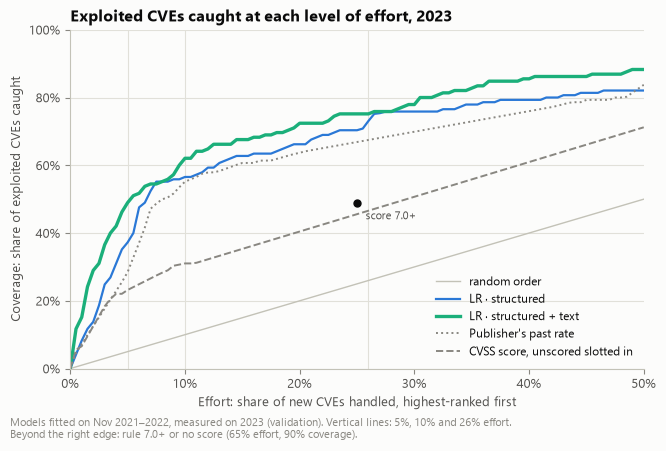

In [30]:
def coverage_curves(y, scores, styles, rules, title, name, note):
    "Coverage against effort (0-50%) for several rankings, with the Q1 rules as points."
    efforts = np.linspace(0, 0.5, 101)
    fig, ax = plt.subplots(figsize=(7.4, 4.4))
    ax.plot([0, 0.5], [0, 0.5], color=AXIS, linewidth=1, label="random order")
    for label, (color, width, dash) in styles.items():
        ax.plot(efforts, coverage(Ranking(scores[label]), y, efforts)[0], color=color, linewidth=width,
                linestyle=dash, label=label)
    beyond = [f"{r.replace('rule: ', '')} ({e:.0%} effort, {c:.0%} coverage)" for r, (e, c) in rules.items() if e > 0.5]
    for rule, (effort, cov) in ((r, ec) for r, ec in rules.items() if ec[0] <= 0.5):
        ax.plot(effort, cov, "o", color=INK, markersize=5, zorder=4)
        ax.annotate(rule.replace("rule: ", ""), (effort, cov), xytext=(6, -12), textcoords="offset points",
                    fontsize=8, color=INK_2)
    for e in EFFORTS:
        ax.axvline(e, color=GRID, linewidth=0.8, zorder=0)
    ax.set_xlim(0, 0.5)
    ax.set_ylim(0, 1.0)
    ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.grid(axis="y")
    ax.set_xlabel("Effort: share of new CVEs handled, highest-ranked first")
    ax.set_ylabel("Coverage: share of exploited CVEs caught")
    ax.set_title(title)
    ax.legend(loc="lower right", fontsize=8.5)
    save_figure(fig, name, note + (f"\nBeyond the right edge: rule {'; '.join(beyond)}." if beyond else ""))

STYLES = {BEST_STRUCTURED: (SET_COLORS["structured"], 1.6, "-"),
          FINAL: (SET_COLORS[CANDIDATES[FINAL]["feature_set"]], 2.4, "-"),   # replaces the line above if the same model
          "Publisher's past rate": (BASELINE_GREY, 1.4, ":"),
          "CVSS score, unscored slotted in": (BASELINE_GREY, 1.4, "--")}
coverage_curves(y_val, val_scores, STYLES, RULES_VALIDATE, "Exploited CVEs caught at each level of effort, 2023",
                "q2_coverage_validation", "Models fitted on Nov 2021–2022, measured on 2023 (validation). "
                "Vertical lines: 5%, 10% and 26% effort.")

**Reading the chart:** the higher a curve, the more exploited CVEs a team catches for the same work.
The diagonal is a random order. Where the final model's curve passes above a dot, the model catches
more than that Q1 rule at the same effort. (If the final model is itself the best structured-only
model, the two lines coincide.)

---

## Stage F · What the description adds, and the PyTorch decision

### Step 17 · The text ablation

**What we are doing:** measuring, on 2023, with paired bootstrap intervals:

- **text added to structured:** coverage of "structured + text" minus "structured", per family;
- **text alone vs structured alone:** coverage of "text" minus "structured", per family;
- **text alone vs a random order:** coverage of "text" minus the effort (a random order catches, on
  average, exactly the share it handles);
- **best with text vs best structured:** the best "structured + text" model minus the best
  "structured" model, across families. This is the comparison the PyTorch rule uses.

**Why:** a difference whose interval excludes zero is larger than chance would produce in a year
with 145 exploited CVEs. One caveat, stated in the report: each candidate was chosen on this same
year, so its 2023 coverage is slightly optimistic; the test year (Stage G) has no such bias.

In [31]:
def ablation_rows(family_short, efforts=(PRIMARY_EFFORT, 0.26)):
    "The three text comparisons of one family, at each effort."
    s, t, st = (f"{family_short} · {fs}" for fs in FEATURE_SETS)
    rows = []
    for e in efforts:
        for label, a, b in [("text added to structured", s, st), ("text alone vs structured alone", s, t)]:
            rows.append((family_short, label, e, *difference(q2_val, boot_val, a, b, e)))
        i, cov = EFFORTS.index(e), q2_val.loc[t, f"coverage_{tag(e)}"]
        low, high = np.percentile(boot_val[:, list(q2_val.index).index(t), i] - e, [2.5, 97.5])
        rows.append((family_short, "text alone vs random order", e, cov - e, low, high))
    return rows

rows = ablation_rows("LR") + ablation_rows("GBM")
for e in (PRIMARY_EFFORT, 0.26):
    rows.append(("best of each", f"{BEST_WITH_TEXT} vs {BEST_STRUCTURED}", e,
                 *difference(q2_val, boot_val, BEST_STRUCTURED, BEST_WITH_TEXT, e)))
q2_ablation = pd.DataFrame(rows, columns=["family", "comparison", "effort", "change", "low", "high"])
q2_ablation["clear"] = (q2_ablation["low"] > 0) | (q2_ablation["high"] < 0)
print(q2_ablation.to_string(index=False, formatters={"effort": "{:.0%}".format, "change": "{:+.1%}".format,
                                                     "low": "{:+.1%}".format, "high": "{:+.1%}".format}))
save_table(q2_ablation, "q2_text_ablation", index=False)

      family                                comparison effort change    low   high  clear
          LR                  text added to structured    10%  +5.5%  +0.7% +10.4%   True
          LR            text alone vs structured alone    10%  +4.1%  -4.3% +12.8%  False
          LR                text alone vs random order    10% +50.7% +42.9% +58.3%   True
          LR                  text added to structured    26%  +2.1%  -2.3%  +7.0%  False
          LR            text alone vs structured alone    26% +11.7%  +4.4% +20.1%   True
          LR                text alone vs random order    26% +58.8% +53.2% +64.4%   True
         GBM                  text added to structured    10%  +6.2%  -1.9% +14.5%  False
         GBM            text alone vs structured alone    10%  +3.4%  -6.5% +13.2%  False
         GBM                text alone vs random order    10% +41.7% +33.4% +50.1%   True
         GBM                  text added to structured    26%  +6.2%  -0.9% +13.3%  False
         G

WindowsPath('results/q2_text_ablation.csv')

**Reading the result:** each row is a change in coverage (in percentage points) with its 95%
interval; `clear` is `True` when the interval excludes zero. "Text alone vs random order" shows
whether the wording carries signal at all; "text added to structured" shows whether that signal is
*new*, or already captured by the publisher, CWE and vector.

*In the run of 15 Nov 2026:* for logistic regression, text adds +5.5 points at 10% effort (clear) and +2.1
at 26% (not clear), and text alone beats a random order by +50.7 points. For gradient boosting the
gains (+6.2 at 10%, +6.2 at 26%) have intervals that include zero.

The chart below shows the six candidates side by side at 10% effort, with the two strongest
baselines as reference lines.

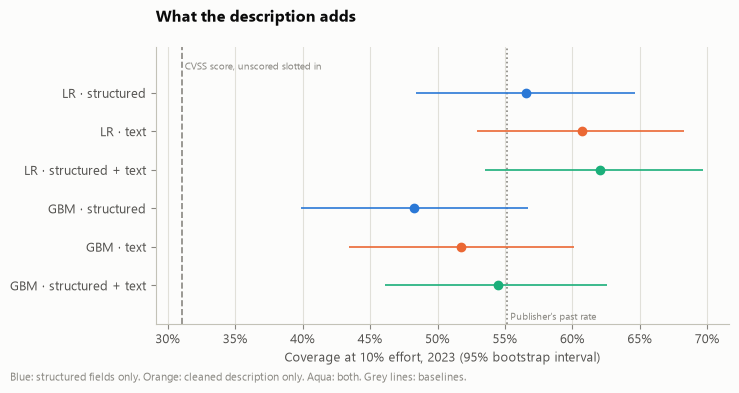

In [32]:
fig, ax = plt.subplots(figsize=(7.4, 3.6))
names = list(CANDIDATES)[::-1]
y_pos = np.arange(len(names))
for y_i, name in zip(y_pos, names):
    est, low, high = q2_val.loc[name, [primary, f"{primary}_low", f"{primary}_high"]]
    color = SET_COLORS[CANDIDATES[name]["feature_set"]]
    ax.errorbar(est, y_i, xerr=[[est - low], [high - est]], fmt="o", color=color, ecolor=color,
                elinewidth=1.2, markersize=6, zorder=3)
for ref, dash, y_text in (("CVSS score, unscored slotted in", "--", len(names) - 0.45),
                          ("Publisher's past rate", ":", -0.95)):       # one label above the dots, one below
    ax.axvline(q2_val.loc[ref, primary], color=BASELINE_GREY, linestyle=dash, linewidth=1.2, zorder=1)
    ax.text(q2_val.loc[ref, primary], y_text, f" {ref}", fontsize=7.5, color=INK_3, va="bottom")
ax.set_yticks(y_pos, names)
ax.set_ylim(-1.0, len(names) + 0.2)
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.grid(axis="x")
ax.set_axisbelow(True)
ax.set_xlabel(f"Coverage at {PRIMARY_EFFORT:.0%} effort, 2023 (95% bootstrap interval)")
ax.set_title("What the description adds", pad=18)
save_figure(fig, "q2_text_ablation", "Blue: structured fields only. Orange: cleaned description only. "
            "Aqua: both. Grey lines: baselines.")

**Reading the chart:** within each family, compare the aqua dot (both) with the blue one
(structured): if it sits clearly to the right, the text adds signal. The orange dot shows what the
text achieves on its own.

### Step 18 · Sensitivity checks

**What we are doing:** re-measuring every ranking on 2023 in three variations.

1. **Without CVEs listed before publication:** the proposal committed to reporting results with and
   without them, because their outcome was already known when the record appeared.
2. **Without the WordPress plug-in publishers:** they issue many CVEs that are almost never exploited,
   so a model could look good just by ranking them last.
3. **With the uncleaned description:** the best "structured + text" model of each family, refitted
   on the original text. The gap shows how much the exploitation phrases would have added, which is
   the size of the leak the cleaning prevents (or of the fair signal it gives up).

In [33]:
val = frames["validate"]
keep_after = ~val["kev_before_publication"].to_numpy(bool)
keep_no_wp = ~is_wordpress(val).to_numpy(bool)
for f in frames.values():
    f["text_uncleaned"] = f["description"].fillna("")
_, _, feats_raw = build_features(frames["train"], frames, text_column="text_uncleaned")
uncleaned = {}
for family, (fam, _) in FAMILIES.items():
    c = CANDIDATES[f"{SHORT[family]} · structured + text"]
    X_train, categorical = design(feats_raw["train"], fam, "structured + text")
    model = fit_model(family, c["params"], X_train, y_train, categorical)
    X_val_raw, _ = design(feats_raw["validate"], fam, "structured + text")
    uncleaned[f"{SHORT[family]} · structured + text"] = predict(model, X_val_raw)

def coverage_row(y, score, mask=None):
    "Coverage at each effort for one ranking, optionally on a subset of CVEs."
    mask = np.ones(len(y), dtype=bool) if mask is None else mask
    return coverage(Ranking(score[mask]), y[mask], EFFORTS)[0]

rows = {}
for name, score in val_scores.items():
    rows[name] = {**{f"all_{tag(e)}": v for e, v in zip(EFFORTS, coverage_row(y_val, score))},
                  **{f"after_publication_{tag(e)}": v for e, v in zip(EFFORTS, coverage_row(y_val, score, keep_after))},
                  **{f"no_wordpress_{tag(e)}": v for e, v in zip(EFFORTS, coverage_row(y_val, score, keep_no_wp))}}
    if name in uncleaned:
        cov_raw = coverage_row(y_val, uncleaned[name])
        rows[name].update({f"uncleaned_text_{tag(e)}": v for e, v in zip(EFFORTS, cov_raw)})
q2_sensitivity = pd.DataFrame(rows).T
shown = [c for c in q2_sensitivity.columns if c.endswith(f"_{tag(PRIMARY_EFFORT)}")]
print(f"coverage at {PRIMARY_EFFORT:.0%} effort, 2023:\n")
print(q2_sensitivity[shown].to_string(float_format=lambda v: f"{v:.1%}", na_rep="–"))
save_table(q2_sensitivity, "q2_sensitivity_validation")

coverage at 10% effort, 2023:

                                 all_10  after_publication_10  no_wordpress_10  uncleaned_text_10
CVSS score, unscored last         31.0%                 32.6%            30.7%                  –
CVSS score, unscored slotted in   31.0%                 32.6%            30.7%                  –
Publisher's past rate             55.2%                 54.8%            50.8%                  –
LR · structured                   56.6%                 56.8%            55.9%                  –
LR · text                         60.7%                 58.3%            57.2%                  –
LR · structured + text            62.1%                 62.1%            55.9%              64.8%
GBM · structured                  48.3%                 47.7%            45.9%                  –
GBM · text                        51.7%                 52.3%            48.3%                  –
GBM · structured + text           54.5%                 55.3%            51.0%         

WindowsPath('results/q2_sensitivity_validation.csv')

**Reading the result:** coverage at 10% effort for every ranking, on all 2023 CVEs, without the
pre-publication listings, without WordPress publishers, and (for the two "structured + text" models)
with the uncleaned text. All efforts are in `results/q2_sensitivity_validation.csv`. Rankings that
hold their order across the columns are robust; a large jump in the last column means the
exploitation phrases carry a lot of signal.

*In the run of 15 Nov 2026:* the final model catches 62.1% on all 2023 CVEs and 62.1% without the
pre-publication listings, so those cases do not drive it. Without the WordPress publishers every
ranking loses a few points (the final model 55.9%): their many never-exploited CVEs were easy to rank
last. The order of the rankings holds. With the uncleaned text the final model would reach 64.8%
(+2.7 points): roughly what the exploitation phrases would add, and what the cleaning gives up.

### Step 19 · What the logistic regression learned

**What we are doing:** refitting the "structured + text" logistic regression with its chosen
setting and listing the inputs with the largest positive and negative weights.

**Why:** this makes the model inspectable. A sensible model should push up, for example, certain
publishers, network attack vectors, and words such as "remote code execution"; a weight on a word
that only makes sense after exploitation would point to a leak the cleaning missed.

                                  weight        kind
publisher: Microsoft Corporation  +3.292  structured
publisher: Atlassian              +2.061  structured
publisher: VMware                 +2.017  structured
publisher: Chrome                 +2.001  structured
word: mivoice                     +1.948        text
word: veeam                       +1.874        text
word: code injection              +1.746        text
word: remote                      +1.731        text
word: zimbra                      +1.683        text
word: replication                 +1.672        text
cwe: CWE-665                      +1.641  structured
word: unauthenticated             +1.629        text
cwe: CWE-121                      +1.620  structured
word: aka                         +1.558        text
word: code                        +1.485        text
word: zcs                         +1.457        text
word: remote command              +1.439        text
word: component mitel             +1.438      

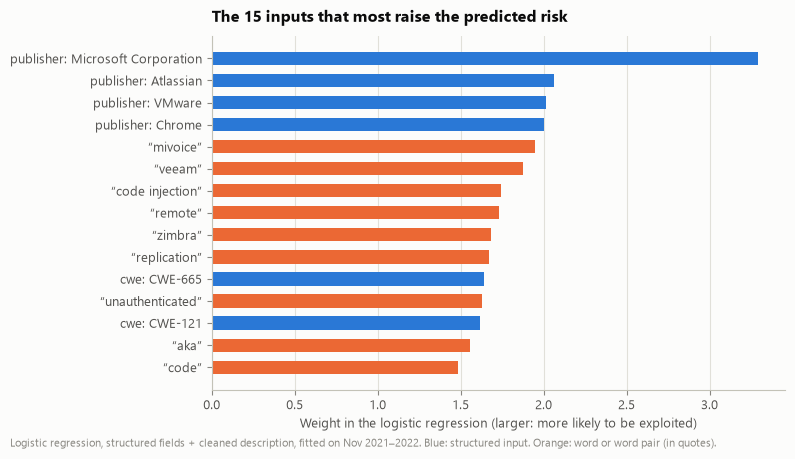

In [34]:
lr_name = "LR · structured + text"
X_train, _ = design(feats["train"], "lr", "structured + text")
lr_model = fit_model("logistic regression", CANDIDATES[lr_name]["params"], X_train, y_train)
weights = pd.Series(lr_model.coef_[0], index=s_enc.names() + t_enc.names())
top = pd.concat([weights.nlargest(20), weights.nsmallest(10)]).rename("weight").to_frame()
top["kind"] = np.where(top.index.str.startswith("word: "), "text", "structured")
print(top.to_string(float_format=lambda v: f"{v:+.3f}"))
save_table(top, "q2_top_features")

fig, ax = plt.subplots(figsize=(7.4, 4.6))
best15 = weights.nlargest(15)[::-1]
colors = [SET_COLORS["text"] if n.startswith("word: ") else SET_COLORS["structured"] for n in best15.index]
ax.barh(np.arange(len(best15)), best15.to_numpy(), height=0.6, color=colors, zorder=2)
ax.set_yticks(np.arange(len(best15)), [n.replace("word: ", "“") + ("”" if n.startswith("word: ") else "")
                                       for n in best15.index])
ax.grid(axis="x")
ax.set_axisbelow(True)
ax.set_xlabel("Weight in the logistic regression (larger: more likely to be exploited)")
ax.set_title("The 15 inputs that most raise the predicted risk", pad=10)
save_figure(fig, "q2_top_features", "Logistic regression, structured fields + cleaned description, fitted on "
            "Nov 2021–2022. Blue: structured input. Orange: word or word pair (in quotes).")

**Reading the result:** the 20 most positive and 10 most negative weights, and a chart of the top
15 (blue for structured inputs such as `publisher: …` or `AV: N`, orange for words in quotes). The
weights apply to standardised or 0/1 inputs, so their sizes are comparable within each kind. Words
that name a product or a vendor often stand in for the publisher.

*In the run of 15 Nov 2026:* the top inputs are four publishers (Microsoft, Atlassian, VMware, Chrome),
product names ("mivoice", "veeam", "zimbra", and "replication" from Veeam Backup & Replication),
attack words ("code injection", "remote", "unauthenticated") and two CWEs. "aka" comes from
Microsoft's way of naming its CVEs, so it stands in for the publisher. The most negative are PR: H,
I: N, GitHub, CVSS version 3.0, ICS-CERT, Siemens and WPScan. No word about exploitation appears.

### Step 20 · The go/no-go rule for the PyTorch extension

**What we are doing:** applying the rule agreed before any model was run (saved in the project as
the PyTorch extension plan), to the comparison "best with text vs best structured" at 10% effort:

| What 2023 shows | Decision |
|:--|:--|
| the text clearly adds coverage (interval above zero) | **go** |
| it adds little, but the interval is wider than 10 points | **go, framed as exploratory** |
| it adds nothing and the interval is narrow | **probably skip**: spend the time on Q4 and the demo |

The audit of Stage C is part of the rule: the decision must rest on cleaned text, which it does here
by construction. The result is saved in `results/q2_pytorch_decision.json`.

In [35]:
est, low, high = difference(q2_val, boot_val, BEST_STRUCTURED, BEST_WITH_TEXT, PRIMARY_EFFORT)
if low > 0:
    decision, why = "go", "the description clearly adds coverage beyond the structured fields"
elif high - low > WIDE_INTERVAL:
    decision, why = "go, framed as exploratory", "the gain is uncertain: the interval is too wide to settle it"
else:
    decision, why = "probably skip", "the description adds no clear coverage, and the interval is narrow"
q2_decision = {
    "comparison": f"{BEST_WITH_TEXT} minus {BEST_STRUCTURED}, coverage at {PRIMARY_EFFORT:.0%} effort, 2023",
    "change": est, "interval": [low, high], "interval_width": high - low, "decision": decision, "reason": why,
    "text_alone_vs_random": q2_ablation[(q2_ablation["comparison"] == "text alone vs random order")
                                        & (q2_ablation["effort"] == PRIMARY_EFFORT)]
                            [["family", "change", "low", "high"]].to_dict("records"),
    "description_audit": {"with_phrase": int(len(audit_pool)), "histories_retrieved": read,
                          "phrase_added_after_kev": late,
                          "text_used": "cleaned (sentences stating exploitation removed)"},
}
print(f"{q2_decision['comparison']}:\n  change {est:+.1%} (95% interval {low:+.1%} to {high:+.1%})")
print(f"\ndecision: {decision.upper()} – {why}")
save_json(q2_decision, RESULTS / "q2_pytorch_decision.json")

LR · structured + text minus LR · structured, coverage at 10% effort, 2023:
  change +5.5% (95% interval +0.7% to +10.4%)

decision: GO – the description clearly adds coverage beyond the structured fields


**Reading the result:** the change in coverage with its interval, and the decision with its reason.
This is a recommendation for planning, not a verdict on the extension's value: an embedding model
may capture meaning that word counts miss even when TF-IDF adds little.

*In the run of 15 Nov 2026:* +5.5 points (+0.7 to +10.4): **go**.

**Is PyTorch installable here?** The next cell checks whether `torch` and `sentence-transformers`
are installed and, if not, whether PyPI offers a `torch` build for this Python version and system
(one small request to `pypi.org`, nothing is downloaded). The check is `WARN` if neither can be
confirmed; it does not affect any result.

In [36]:
import importlib.util

def torch_build_available():
    "(latest torch version, whether PyPI has a build for this Python and system), or (None, None) if unknown."
    python_tag = f"cp{sys.version_info.major}{sys.version_info.minor}"
    system = {"win32": "win", "darwin": "macosx", "linux": "linux"}.get(sys.platform, sys.platform)
    try:
        resp = requests.get("https://pypi.org/pypi/torch/json", timeout=30)
        resp.raise_for_status()
        info = resp.json()
        files = [f["filename"] for f in info.get("urls", [])]
        return info["info"]["version"], any(python_tag in f and system in f for f in files)
    except (requests.RequestException, KeyError, ValueError):
        return None, None

installed = {m: importlib.util.find_spec(m) is not None for m in ("torch", "sentence_transformers")}
latest, build = (None, None) if installed["torch"] else torch_build_available()
print(f"installed: {installed}")
if not installed["torch"]:
    print(f"PyPI: torch {latest} " + ("has a build for this Python and system" if build else
          "has no build for this Python and system" if build is False else "could not be checked"))
ready = installed["torch"] or bool(build)
check("F1-pytorch-readiness", True if ready else None, installed=installed, pypi_build=build)

installed: {'torch': False, 'sentence_transformers': False}
PyPI: torch 2.15.0 has a build for this Python and system
PASS  F1-pytorch-readiness  |  {'installed': {'torch': False, 'sentence_transformers': False}, 'pypi_build': True}


**Reading the result:** `PASS` when `torch` is installed or installable; `WARN` otherwise (for
example, no build yet for a brand-new Python version, or no network).

*In the run of 15 Nov 2026:* `torch` and `sentence-transformers` are not installed yet; PyPI has a
`torch` build (2.15.0) for this Python and system, so the extension can be installed when needed.

---

## Stage G · The test year

### Step 21 · Freeze every choice before 2024 is touched

**What we are doing:** writing down everything decided so far (the six candidates and their
settings, the final model, the baselines' rules, the feature settings) in `results/q2_selection.json`,
together with a SHA-256 fingerprint of that content.

**Why:** this is the evidence that the test result is honest. The fingerprint changes if any choice
changes, and Step 22 records it every time the test year is opened. A report can then show that 2024
was scored with choices fixed beforehand, and how many times it was opened.

In [37]:
SELECTION = {
    "final_model": FINAL, "best_structured": BEST_STRUCTURED, "best_with_text": BEST_WITH_TEXT,
    "candidates": CANDIDATES,
    "baselines": {"unscored_cvss_band": unscored_band, "publisher_pseudo_cves": 50},
    "settings": {"min_category": MIN_CATEGORY, "max_categories": MAX_CATEGORIES, "tfidf": TFIDF,
                 "svd_components": SVD_COMPONENTS, "efforts": EFFORTS, "primary_effort": PRIMARY_EFFORT,
                 "seed": SEED, "text": "cleaned: sentences stating exploitation removed"},
    "validation_coverage": {name: round(float(v), 6) for name, v in q2_val.loc[list(CANDIDATES), primary].items()},
}
SELECTION_SHA = hashlib.sha256(json.dumps(SELECTION, sort_keys=True, default=str).encode("utf-8")).hexdigest()
save_json({"sha256": SELECTION_SHA, "frozen_at": now_iso(), **SELECTION}, RESULTS / "q2_selection.json")
print(f"final model: {FINAL} {CANDIDATES[FINAL]['params']}")
print(f"selection fingerprint: {SELECTION_SHA[:16]}…")
check("G1-selection-frozen", True, sha256=SELECTION_SHA, final_model=FINAL)

final model: LR · structured + text {'C': 0.1}
selection fingerprint: 86f7a97f7255a446…
PASS  G1-selection-frozen  |  {'sha256': '86f7a97f7255a4465e881882e555faf5bcf1dba63651c53ee7fa518468716703', 'final_model': 'LR · structured + text'}


**Reading the result:** the final model and the first 16 characters of the fingerprint. Running the
notebook again with the same data and settings gives the same fingerprint.

*In the run of 15 Nov 2026:* on the project laptop the fingerprint was `86f7a97f7255a446…`. Gradient
boosting's results depend slightly on library versions (a cloud copy with newer versions gave
another fingerprint, with the same final model), so open the test year on the same computer.

### Step 22 · Scoring 2024, once

**What we are doing:** two functions, run only when `EVALUATE_TEST = True`.

- `open_test_year` records the opening (time and fingerprint) in `logs/test_openings.json`, then
  loads the 2024 rows and cleans their descriptions exactly as before.
- `score_test_year` refits every candidate **on training plus validation** (Nov 2021–2023) with its
  frozen settings, refits the encoders and baselines on the same rows, and scores 2024.

**Why refit on both years:** a team deploying the model at the start of 2024 would use every labelled
CVE it had, and 2023 adds 145 exploited CVEs to the 128 of the training period. The settings stay
exactly those chosen on 2023; only the fitting data grows.

In [38]:
OPENINGS = LOGS / "test_openings.json"

def open_test_year():
    "Log this opening of the test year, then return its rows, cleaned like the others, and earlier fingerprints."
    openings = json.loads(OPENINGS.read_text(encoding="utf-8")) if OPENINGS.exists() else []
    earlier = sorted({o["selection_sha256"] for o in openings})
    openings.append({"opened": now_iso(), "selection_sha256": SELECTION_SHA, "final_model": FINAL})
    save_json(openings, OPENINGS)
    test = period_frame("test")
    test["text"] = test["description"].map(mask_exploitation)
    return test, earlier

def score_test_year(test):
    "Refit encoders, baselines and every candidate on Nov 2021-2023 with the frozen settings; score 2024."
    fit_df = pd.concat([frames["train"], frames["validate"]], ignore_index=True)
    y_fit = fit_df[LABEL].to_numpy(int)
    _, _, encoded = build_features(fit_df, {"fit": fit_df, "test": test})
    scores, band = cvss_baselines(fit_df, test)
    scores["Publisher's past rate"] = publisher_baseline(fit_df, test)
    for name, c in CANDIDATES.items():
        fam = FAMILIES[c["family"]][0]
        X_fit, categorical = design(encoded["fit"], fam, c["feature_set"])
        model = fit_model(c["family"], c["params"], X_fit, y_fit, categorical)
        scores[name] = predict(model, design(encoded["test"], fam, c["feature_set"])[0])
    return scores, band

**Running it:** the next cell either reports that the test year is sealed, or opens it, scores it
and builds the same table as for 2023.

In [39]:
if not EVALUATE_TEST:
    print("The test year (2024) is sealed: no 2024 label has been read.\n"
          "When the validation results above are final, run 03_model_test.ipynb (the same notebook, test year on).")
else:
    t0 = time.perf_counter()
    test, earlier = open_test_year()
    y_test = test[LABEL].to_numpy(int)
    test_scores, test_band = score_test_year(test)
    q2_test, boot_test = evaluation_table(y_test, test_scores)
    RULES_TEST = rule_points(test)
    print(f"2024: {len(test):,} CVEs, {int(y_test.sum())} exploited | scored in {time.perf_counter() - t0:.0f} s\n")
    print(q2_test[cols + ["average_precision"]].to_string(float_format=lambda v: f"{v:.1%}"))
    for name, (effort, cov) in RULES_TEST.items():
        print(f"{name:<26} 2024: effort {effort:.1%}, coverage {cov:.1%}")
    save_table(q2_test, "q2_test_results")
    pd.DataFrame({"cve_id": test["cve_id"], **test_scores}).to_parquet(PROCESSED / "model_scores_test.parquet",
                                                                       index=False)
    RUN["files"].append(str(PROCESSED / "model_scores_test.parquet"))
    reopened = [sha for sha in earlier if sha != SELECTION_SHA]
    if reopened:
        print(f"\nnote: the test year was opened before with {len(reopened)} other selection(s): report every opening")
    check("G2-test-evaluated", None if reopened else True, cves=len(test), exploited=int(y_test.sum()),
          other_selections_before=len(reopened))

The test year (2024) is sealed: no 2024 label has been read.
When the validation results above are final, run 03_model_test.ipynb (the same notebook, test year on).


**Reading the result:** (only when the test year is opened) the same table as Step 16, now for 2024,
with the two Q1 rules. The final model's row is the headline result of Q2. `G2` is `PASS` when every
earlier opening used the same frozen choices, and `WARN` if the choices changed in between, in which
case the report should mention every opening. The 2024 scores of every ranking are saved in
`data/processed/model_scores_test.parquet` for the EPSS comparison (Q4).

**The differences and the chart:** the next cell measures the final model against the baselines and
the text gain on 2024, with paired intervals, repeats the two sensitivity checks, and draws the curves.

In [40]:
if EVALUATE_TEST:
    comparisons = [(base, FINAL) for base in ("CVSS score, unscored slotted in", "Publisher's past rate")]
    comparisons.append((BEST_STRUCTURED, BEST_WITH_TEXT))
    q2_test_diff = pd.DataFrame([(b, a, e, *difference(q2_test, boot_test, a, b, e))
                                 for a, b in comparisons for e in EFFORTS],
                                columns=["model", "compared_with", "effort", "change", "low", "high"])
    q2_test_diff["clear"] = (q2_test_diff["low"] > 0) | (q2_test_diff["high"] < 0)
    print(q2_test_diff.to_string(index=False, formatters={"effort": "{:.0%}".format, "change": "{:+.1%}".format,
                                                          "low": "{:+.1%}".format, "high": "{:+.1%}".format}))
    save_table(q2_test_diff, "q2_test_differences", index=False)

    after, no_wp = ~test["kev_before_publication"].to_numpy(bool), ~is_wordpress(test).to_numpy(bool)
    sens = {}
    for name, s in test_scores.items():
        sens[name] = {**{f"after_publication_{tag(e)}": v for e, v in zip(EFFORTS, coverage_row(y_test, s, after))},
                      **{f"no_wordpress_{tag(e)}": v for e, v in zip(EFFORTS, coverage_row(y_test, s, no_wp))}}
    q2_test_sens = pd.DataFrame(sens).T
    save_table(q2_test_sens, "q2_sensitivity_test")
    coverage_curves(y_test, test_scores, STYLES, RULES_TEST,
                    "Exploited CVEs caught at each level of effort, 2024 (test)", "q2_coverage_test",
                    "Models fitted on Nov 2021–2023 with the settings frozen on 2023, "
                    "measured once on 2024. Vertical lines: 5%, 10% and 26% effort.")
else:
    print("sealed: nothing to compare yet")

sealed: nothing to compare yet


**Reading the result:** each row is the final model (or the best model with text) minus a baseline
(or the best structured model), at each effort, with its 95% interval; `clear` is `True` when the
interval excludes zero. The chart is the 2024 version of the one in Step 16.

---

## Stage H · Summary

### Step 23 · Key findings, checks and files

**What we are doing:** collecting the headline numbers into the summary file (`results/q2_summary.json`,
or `q2_summary_test.json` in the test-year copy), then listing every check and file and saving the run
log (`logs/model_log.json`, or `model_log_test.json`).

**Why:** the report, the slides and the EPSS notebook take their numbers from these files, never
copied by hand.

In [41]:
def at(table_, name, effort):
    "Coverage of one ranking at one effort, with its interval, as text."
    est, low, high = (table_.loc[name, f"coverage_{tag(effort)}{s}"] for s in ("", "_low", "_high"))
    return f"{est:.1%} ({low:.1%}–{high:.1%})"

CVSS_BASE, PUBLISHER_BASE = "CVSS score, unscored slotted in", "Publisher's past rate"
gain, (gain_low, gain_high) = q2_decision["change"], q2_decision["interval"]
FINDINGS = {
    "final model": f"{FINAL}, settings {CANDIDATES[FINAL]['params']} (chosen on 2023 at {PRIMARY_EFFORT:.0%} effort)",
    "2023 coverage, final model": "; ".join(f"{e:.0%} effort: {at(q2_val, FINAL, e)}" for e in EFFORTS),
    "2023 coverage, CVSS baseline": "; ".join(f"{e:.0%} effort: {at(q2_val, CVSS_BASE, e)}" for e in EFFORTS),
    "2023 coverage, publisher baseline": "; ".join(f"{e:.0%} effort: {at(q2_val, PUBLISHER_BASE, e)}" for e in EFFORTS),
    "2023 rules": "; ".join(f"{n.replace('rule: ', '')}: effort {e:.0%}, coverage {c:.0%}"
                            for n, (e, c) in RULES_VALIDATE.items()),
    "text adds (2023)": f"{gain:+.1%} ({gain_low:+.1%} to {gain_high:+.1%}) at {PRIMARY_EFFORT:.0%} effort; "
                        f"PyTorch extension: {q2_decision['decision']}",
    "description audit": AUDIT_SUMMARY,
}
if EVALUATE_TEST:
    FINDINGS["2024 coverage, final model"] = "; ".join(f"{e:.0%} effort: {at(q2_test, FINAL, e)}" for e in EFFORTS)
    FINDINGS["2024 coverage, CVSS baseline"] = "; ".join(f"{e:.0%} effort: {at(q2_test, CVSS_BASE, e)}"
                                                       for e in EFFORTS)
    FINDINGS["2024 coverage, publisher baseline"] = "; ".join(f"{e:.0%} effort: {at(q2_test, PUBLISHER_BASE, e)}"
                                                            for e in EFFORTS)
    FINDINGS["2024 rules"] = "; ".join(f"{n.replace('rule: ', '')}: effort {e:.0%}, coverage {c:.0%}"
                                       for n, (e, c) in RULES_TEST.items())
for topic, text in FINDINGS.items():
    print(f"- {topic}: {text}")
save_json(FINDINGS, SUMMARY_FILE)

- final model: LR · structured + text, settings {'C': 0.1} (chosen on 2023 at 10% effort)
- 2023 coverage, final model: 5% effort: 49.0% (40.0%–56.7%); 10% effort: 62.1% (53.5%–69.7%); 26% effort: 75.2% (67.8%–82.1%)
- 2023 coverage, CVSS baseline: 5% effort: 23.2% (16.9%–30.4%); 10% effort: 31.0% (24.3%–38.7%); 26% effort: 46.6% (40.5%–53.2%)
- 2023 coverage, publisher baseline: 5% effort: 28.5% (21.3%–36.1%); 10% effort: 55.2% (47.1%–63.8%); 26% effort: 67.5% (60.1%–74.6%)
- 2023 rules: score 7.0+: effort 25%, coverage 49%; 7.0+ or no score: effort 65%, coverage 90%
- text adds (2023): +5.5% (+0.7% to +10.4%) at 10% effort; PyTorch extension: go
- description audit: 148 training/validation descriptions state exploitation; 148 histories retrieved; of the 37 exploited: 4 had the phrase at publication, 6 gained it later (6 of them already in KEV before publication), 27 cannot be dated; models use cleaned text


**Reading the result:** one line per headline finding. Coverage figures carry their 95% intervals in
brackets.

**The checks and files:** the last cell lists every check and every file this run wrote, and saves
the run log.

In [42]:
EXPECTED_CHECKS = ["A1-evaluation-selftest", "B1-table-loaded", "B2-inputs-permitted", "C1-description-masking",
                   "C2-description-history", "D0-cvss-parser-selftest", "D1-features-built", "E1-models-trained",
                   "F1-pytorch-readiness", "G1-selection-frozen"]
EXPECTED_CHECKS += ["G2-test-evaluated"] if EVALUATE_TEST else []
for name in EXPECTED_CHECKS:
    RUN["checks"].setdefault(name, {"verdict": "FAIL", "error": "check never ran"})
RUN["finished"] = now_iso()
LOG_FILE.write_text(json.dumps(RUN, indent=2, default=str), encoding="utf-8")

verdicts = [c["verdict"] for c in RUN["checks"].values()]
print(f"{verdicts.count('PASS')}/{len(verdicts)} checks passed, {verdicts.count('WARN')} to review, "
      f"{verdicts.count('FAIL')} failed | test year {'opened' if EVALUATE_TEST else 'sealed'}")
for name, c in RUN["checks"].items():
    print(f"  {c['verdict']:<5} {name}")
print(f"\n{len(RUN['files'])} files written:")
for path in RUN["files"]:
    print(f"  {path}")

10/10 checks passed, 0 to review, 0 failed | test year sealed
  PASS  A1-evaluation-selftest
  PASS  B1-table-loaded
  PASS  B2-inputs-permitted
  PASS  C1-description-masking
  PASS  C2-description-history
  PASS  D0-cvss-parser-selftest
  PASS  D1-features-built
  PASS  E1-models-trained
  PASS  F1-pytorch-readiness
  PASS  G1-selection-frozen

15 files written:
  results\q2_description_phrases.csv
  results\q2_description_history.csv
  results\q2_validation_grid.csv
  results\q2_validation_models.csv
  data\processed\model_scores_validate.parquet
  results\q2_validation_differences.csv
  figures\q2_coverage_validation.png
  results\q2_text_ablation.csv
  figures\q2_text_ablation.png
  results\q2_sensitivity_validation.csv
  results\q2_top_features.csv
  figures\q2_top_features.png
  results\q2_pytorch_decision.json
  results\q2_selection.json
  results\q2_summary.json


**Reading the result:** the target is 10 of 10 checks passed with the test year sealed (11 of 11 once
it is opened). `C2` may be `WARN` if the NVD could not be reached for the change histories, and `F1`
if no PyTorch build could be confirmed; neither affects the model results.

## What comes next

1. **Review the 2023 results** (Stages E and F) and the PyTorch decision in Step 20.
2. **Open the test year once:** run `03_model_test.ipynb`, the same notebook with `EVALUATE_TEST = True`.
   It makes the same choices (check that its selection fingerprint in Step 21 equals this copy's),
   so 2024 is scored with them exactly. This copy's outputs stay as they are.
3. **`03b_random_split_check.ipynb`** (optional, any time after this copy): compares the time-based
   split with random splits on the same 2023 CVEs.
4. **`04_epss_comparison.ipynb` (Q4)** reads `data/processed/model_scores_test.parquet` and compares
   these rankings with EPSS on the same 2024 CVEs.
5. **`05_pytorch_extension.ipynb`**, if Step 20 says go: frozen sentence embeddings of the cleaned
   descriptions with a small network, judged with exactly the same tools as here.